# Week 6 – Fine-tuning a pretrained video transformer (VideoMAE) for shoplifting detection

## 1. Setup and configuration

In [1]:
import os, sys, re, json, random, time, math, shutil, subprocess, zipfile, hashlib, copy, bisect, warnings
from pathlib import Path

def _ensure(import_name, pip_name):
    try:
        __import__(import_name)
    except ImportError:
        print(f"installing {pip_name} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name], check=True)

for _imp, _pip in [("transformers", "transformers"), ("huggingface_hub", "huggingface_hub"),
                   ("sklearn", "scikit-learn"), ("cv2", "opencv-python-headless")]:
    _ensure(_imp, _pip)

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms.v2.functional as TF
import transformers

from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

IN_COLAB = "google.colab" in sys.modules

# ---- where persistent files live (same layout as Week 5) ----
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = Path(os.environ.get("WORK_DIR", "/content/drive/MyDrive/shoplifting_project"))
    DATA_DIR = Path("/content/data")
else:
    WORK_DIR = Path(os.environ.get("WORK_DIR", "./shoplifting_project"))
    DATA_DIR = WORK_DIR / "data"

CACHE_DIR    = WORK_DIR / "cache"            # Week 5 cache: T=16 frames, 144x144 (baseline model)
HF_CACHE_DIR = WORK_DIR / "cache_224"        # new: T=16 frames, 256x256 (VideoMAE, random/centre crop 224)
STUDY_DIR    = WORK_DIR / "cache_Tstudy"     # new: T = 4/8/16/32 frames at 112x112 (frame-count study)
for d in (WORK_DIR, DATA_DIR, CACHE_DIR, HF_CACHE_DIR, STUDY_DIR):
    d.mkdir(parents=True, exist_ok=True)

CFG = dict(
    drive_file_id = "1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-",
    T             = 16,       # frames per clip (justified in Section 6)
    seed          = 42,
    val_frac      = 0.15,
    test_frac     = 0.15,
    num_workers   = int(os.environ.get("NUM_WORKERS", min(4, os.cpu_count() or 1))),
    # ---- Week 5 baseline (unchanged hyper-parameters) ----
    cache_size    = 144,
    img_size      = 128,
    base_batch    = int(os.environ.get("BASE_BATCH", 16)),
    base_epochs   = int(os.environ.get("BASE_EPOCHS", 30)),
    backbone_lr   = 1e-4,
    head_lr       = 1e-3,
    weight_decay  = 1e-2,
    base_patience = 8,
    # ---- pretrained video model ----
    hf_model      = os.environ.get("HF_MODEL", "MCG-NJU/videomae-base-finetuned-kinetics"),
    hf_cache_size = 256,
    hf_batch      = int(os.environ.get("HF_BATCH", 4)),       # per step
    hf_accum      = int(os.environ.get("HF_ACCUM", 2)),       # effective batch = hf_batch * hf_accum
    hf_epochs     = int(os.environ.get("HF_EPOCHS", 12)),
    hf_patience   = 5,
    hf_lr         = 5e-5,     # learning rate of the top transformer block
    hf_layer_decay= 0.8,      # layer-wise LR decay towards the input
    hf_head_lr    = 5e-4,     # new, randomly initialised classifier
    hf_wd         = 0.05,
    hf_warmup_epochs = 1,
)
STUDY_TS, STUDY_SIZE = [4, 8, 16, 32], 112
INCLUDE_TRUE_SCRATCH = os.environ.get("INCLUDE_TRUE_SCRATCH", "0") == "1"   # optional 3rd row: ResNet18 w/o ImageNet weights
BENCH_CPU = os.environ.get("BENCH_CPU", "1") == "1"

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(CFG["seed"])

DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("device:", DEVICE, "| torch", torch.__version__, "| transformers", transformers.__version__)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0), f"({torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB)")
print("work dir:", WORK_DIR.resolve())

device: cuda | torch 2.11.0+cu128 | transformers 5.16.1
GPU: Tesla T4 (14.6 GB)
work dir: /kaggle/working/shoplifting_project


## 2. Dataset: download, metadata, exploration



     0K .......... .......... .......... .......... ..........  0% 4.16M 6m47s
    50K .......... .......... .......... .......... ..........  0% 5.87M 5m48s
   100K .......... .......... .......... .......... ..........  0% 14.8M 4m30s
   150K .......... .......... .......... .......... ..........  0% 10.7M 4m2s
   200K .......... .......... .......... .......... ..........  0% 27.3M 3m26s
   250K .......... .......... .......... .......... ..........  0% 11.5M 3m16s
   300K .......... .......... .......... .......... ..........  0% 16.1M 3m3s
   350K .......... .......... .......... .......... ..........  0% 22.4M 2m50s
   400K .......... .......... .......... .......... ..........  0% 27.5M 2m38s
   450K .......... .......... .......... .......... ..........  0% 27.4M 2m28s
   500K .......... .......... .......... .......... ..........  0% 27.7M 2m20s
   550K .......... .......... .......... .......... ..........  0% 54.2M 2m11s
   600K .......... .......... .......... .......... .

Extracting ...
Videos found: 855


probing videos:   0%|          | 0/855 [00:00<?, ?it/s]

Metadata built.

Clips per class:
 label
normal         531
shoplifting    324

Duration (s) per class:
             count   mean   std  min   25%   50%   75%    max
label                                                        
normal       531.0  13.93  5.37  3.0  11.0  14.0  16.0  74.00
shoplifting  324.0  12.22  3.35  4.0  10.0  12.0  15.0  23.03

Frame resolutions:
 width  height
704    576       855


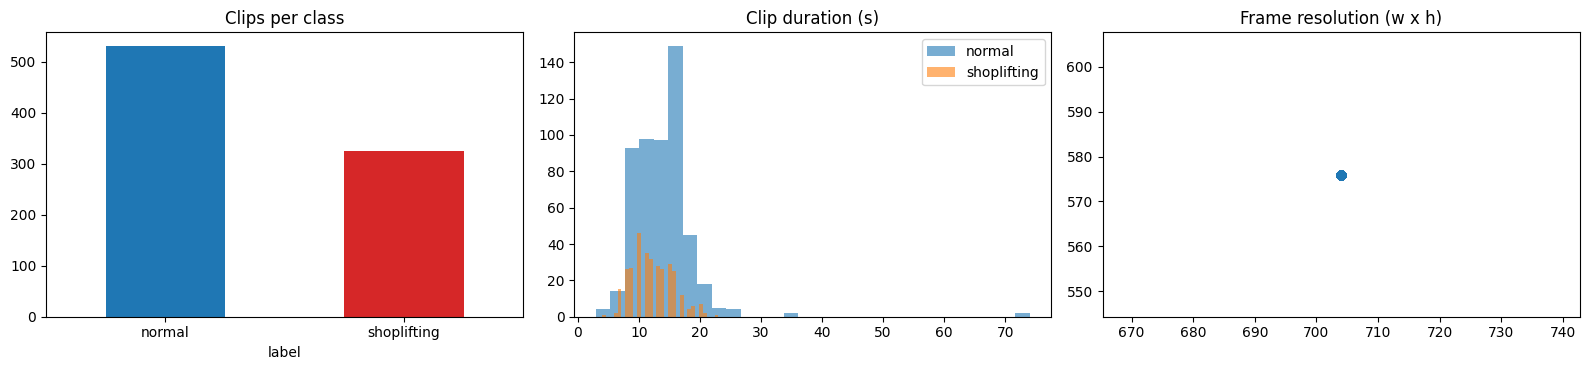

In [2]:
VIDEO_EXTS = {".mp4", ".avi", ".mov", ".mkv", ".mpg", ".mpeg", ".wmv", ".flv", ".webm"}
META_CSV = WORK_DIR / "metadata.csv"
ZIP_PATH = DATA_DIR / "Shop_DataSet.zip"
CLASS_NAMES = ["normal", "shoplifting"]

def list_videos(root):
    return sorted(p for p in Path(root).rglob("*") if p.suffix.lower() in VIDEO_EXTS)

def wget_drive(file_id, out_path):
    url = f"https://drive.usercontent.google.com/download?id={file_id}&export=download&confirm=t"
    subprocess.run(["wget", "--no-check-certificate", "-q", "--show-progress", "-O", str(out_path), url], check=False)
    if not zipfile.is_zipfile(out_path):
        print("wget did not return a zip, falling back to gdown ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
        import gdown
        gdown.download(id=file_id, output=str(out_path), quiet=False)
    assert zipfile.is_zipfile(out_path), "Download failed. Check that the Drive link is public."

def ensure_raw_videos():
    """Make sure the raw videos are on local disk (download + extract only when needed)."""
    vids = list_videos(DATA_DIR)
    if vids:
        return vids
    if not ZIP_PATH.exists():
        wget_drive(CFG["drive_file_id"], ZIP_PATH)
    print("Extracting ...")
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
    ZIP_PATH.unlink(missing_ok=True)
    vids = list_videos(DATA_DIR)
    print("Videos found:", len(vids))
    return vids

def infer_label(path):
    """Label from the parent folder name. Negative keywords are checked first ('non shop lifters' contains 'shop lift')."""
    folder = Path(path).parent.name.lower().replace("_", " ").replace("-", " ")
    if any(k in folder for k in ("non shop", "nonshop", "non-shop", "normal", "not shop")):
        return 0
    if any(k in folder for k in ("shop lift", "shoplift", "theft", "steal")):
        return 1
    return None

def probe_video(path):
    cap = cv2.VideoCapture(str(path))
    n   = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    return n, fps, w, h

def build_metadata():
    videos = ensure_raw_videos()
    assert videos, f"No videos found under {DATA_DIR}"
    rows = []
    for p in tqdm(videos, desc="probing videos"):
        label = infer_label(p)
        if label is None:
            continue
        n, fps, w, h = probe_video(p)
        if n <= 0 or w <= 0:
            print("skipping unreadable video:", p); continue
        rows.append(dict(path=str(p), label=label, n_frames=n, fps=fps, duration=n / fps, width=w, height=h))
    if not rows:
        tree = sorted({str(p.parent.relative_to(DATA_DIR)) for p in videos})[:20]
        raise RuntimeError(f"Could not infer labels from folders. Folders seen: {tree}")
    meta = pd.DataFrame(rows).reset_index(names="id")
    meta.to_csv(META_CSV, index=False)
    return meta

def resolve_paths(df):
    """metadata.csv stores absolute paths. If this is a new session, re-map them to the videos now on disk
    (ids are assigned from the sorted file list, so they stay identical)."""
    if Path(df["path"].iloc[0]).exists():
        return df
    fresh = build_metadata()
    assert len(fresh) == len(df) and (fresh["label"].values == df["label"].values).all(), \
        "Videos on disk do not match metadata.csv - delete metadata.csv / splits.csv and caches and start again."
    return fresh

if META_CSV.exists():
    meta = pd.read_csv(META_CSV); print("Loaded existing metadata.csv")
else:
    meta = build_metadata(); print("Metadata built.")

print("\nClips per class:\n", meta["label"].map(dict(enumerate(CLASS_NAMES))).value_counts().to_string())
print("\nDuration (s) per class:")
print(meta.groupby("label")["duration"].describe().rename(index=dict(enumerate(CLASS_NAMES))).round(2).to_string())
print("\nFrame resolutions:\n", meta.groupby(["width", "height"]).size().sort_values(ascending=False).head(5).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
meta["label"].map(dict(enumerate(CLASS_NAMES))).value_counts().plot.bar(ax=ax[0], color=["tab:blue", "tab:red"], rot=0)
ax[0].set_title("Clips per class")
for lbl, name in enumerate(CLASS_NAMES):
    ax[1].hist(meta.loc[meta.label == lbl, "duration"], bins=30, alpha=.6, label=name)
ax[1].set_title("Clip duration (s)"); ax[1].legend()
ax[2].scatter(meta["width"], meta["height"], alpha=.4); ax[2].set_title("Frame resolution (w x h)")
plt.tight_layout(); plt.show()

## 3. Uniform frame sampling + one-pass multi-resolution decoding

uniform_sample_indices verified for T in [4, 8, 16, 32]


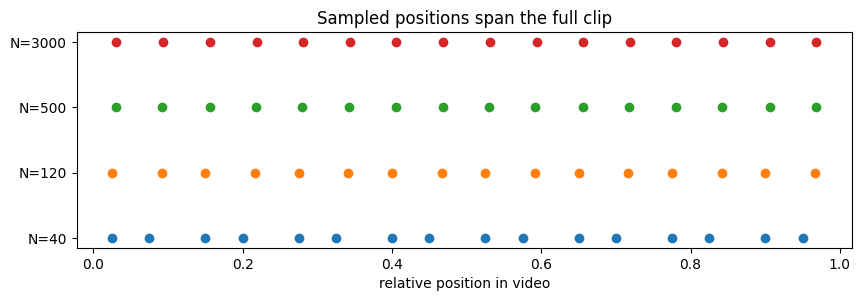

In [3]:
def uniform_sample_indices(n_frames: int, T: int) -> np.ndarray:
    """Return T frame indices spread uniformly over [0, n_frames)."""
    if n_frames <= 0:
        raise ValueError("n_frames must be positive")
    if n_frames < T:                                           
        idx = np.linspace(0, n_frames - 1, T).round()
    else:
        skip = n_frames / T
        idx = np.floor(skip * np.arange(T) + skip / 2)
    return np.clip(idx.astype(int), 0, n_frames - 1)

# ---- verification on clips of very different lengths (as in Week 5, for every T used in this notebook) ----
for T_ in sorted(set(STUDY_TS + [CFG["T"]])):
    for n in [1, 5, 15, 16, 17, 31, 100, 257, 1000, 12345]:
        idx = uniform_sample_indices(n, T_)
        assert len(idx) == T_ and idx.min() >= 0 and idx.max() < n and np.all(np.diff(idx) >= 0)
        if n >= T_:
            skip = n / T_; gaps = np.diff(idx)
            assert gaps.max() - gaps.min() <= 1, "gaps must be uniform within 1 frame"
            assert idx[0] < skip and idx[-1] >= n - skip, "samples must span the whole clip"
print("uniform_sample_indices verified for T in", sorted(set(STUDY_TS + [CFG['T']])))

def count_frames_by_grab(path):
    cap = cv2.VideoCapture(str(path)); n = 0
    while cap.grab():
        n += 1
    cap.release()
    return n

def _decode_at(path, wanted, sizes):
    """Sequentially decode once; return {size: {frame_idx: RGB uint8 (size,size,3)}} for the requested indices."""
    wanted = set(int(i) for i in wanted)
    out = {s: {} for s in sizes}
    cap = cv2.VideoCapture(str(path)); i, last = 0, max(wanted)
    while i <= last:
        ok, frame = cap.read()
        if not ok:
            break
        if i in wanted:
            for s in sizes:
                out[s][i] = cv2.cvtColor(cv2.resize(frame, (s, s), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
        i += 1
    cap.release()
    return out

def read_frames_multi(path, specs, n_hint=None):
    """specs = {key: (T, size)}. Decode the video ONCE and return {key: uint8 array (T, size, size, 3) in RGB}.
    If the container reports a wrong frame count, the video is recounted and decoded again (as in Week 5)."""
    n = n_hint or count_frames_by_grab(path)
    sizes = sorted({s for _, s in specs.values()})
    for attempt in range(2):
        idx = {k: uniform_sample_indices(n, T) for k, (T, s) in specs.items()}
        need = sorted({int(i) for v in idx.values() for i in v})
        got = _decode_at(path, need, sizes)
        if all(int(i) in got[s] for k, (T, s) in specs.items() for i in idx[k]):
            return {k: np.stack([got[s][int(i)] for i in idx[k]]) for k, (T, s) in specs.items()}
        n = count_frames_by_grab(path)
    # last resort: replace frames that cannot be decoded by the nearest decoded one
    res = {}
    for k, (T, s) in specs.items():
        have = sorted(got[s])
        if not have:
            raise RuntimeError(f"Cannot decode {path}")
        def nearest(i, have=have):
            j = bisect.bisect_left(have, i)
            cands = have[max(0, j - 1): j + 1]
            return min(cands, key=lambda c: abs(c - i))
        res[k] = np.stack([got[s][nearest(int(i))] for i in idx[k]])
    return res

def read_sampled_frames(path, T, size, n_hint=None):
    """Week 5 API: uint8 array (T, size, size, 3), RGB."""
    return read_frames_multi(path, {"x": (T, size)}, n_hint)["x"]

fig, ax = plt.subplots(figsize=(10, 2.8))
for k, n in enumerate([40, 120, 500, 3000]):
    ax.scatter(uniform_sample_indices(n, CFG["T"]) / n, [k] * CFG["T"])
ax.set_yticks(range(4)); ax.set_yticklabels(["N=40", "N=120", "N=500", "N=3000"])
ax.set_xlabel("relative position in video"); ax.set_title("Sampled positions span the full clip"); plt.show()

## 4. Build the frame caches (one decoding pass, resumable)
Each video is decoded once; the frames are stored as `uint8 .npy` files written atomically (a crash can never leave a half-written file). Existing Week 5 cache files are re-used.

In [4]:
def atomic_save_npy(path, arr):
    tmp = path.with_name(path.stem + ".tmp.npy")
    np.save(tmp, arr); os.replace(tmp, path)

def study_offsets():
    off, o = {}, 0
    for T_ in STUDY_TS:
        off[T_] = (o, o + T_); o += T_
    return off, o
STUDY_OFFSETS, STUDY_TOTAL = study_offsets()

def cache_job(r):
    """Create every cache file of video r that is still missing (single decode)."""
    p_w5, p_hf, p_st = CACHE_DIR / f"{r.id}.npy", HF_CACHE_DIR / f"{r.id}.npy", STUDY_DIR / f"{r.id}.npy"
    specs = {}
    if not p_w5.exists(): specs["w5"] = (CFG["T"], CFG["cache_size"])
    if not p_hf.exists(): specs["hf"] = (CFG["T"], CFG["hf_cache_size"])
    if not p_st.exists():
        for T_ in STUDY_TS: specs[f"s{T_}"] = (T_, STUDY_SIZE)
    if not specs:
        return None
    try:
        arrs = read_frames_multi(r.path, specs, int(r.n_frames))
        if "w5" in arrs: atomic_save_npy(p_w5, arrs["w5"])
        if "hf" in arrs: atomic_save_npy(p_hf, arrs["hf"])
        if f"s{STUDY_TS[0]}" in arrs:
            atomic_save_npy(p_st, np.concatenate([arrs[f"s{T_}"] for T_ in STUDY_TS]))
        return None
    except Exception as e:
        return (r.id, r.path, str(e))

def missing_cache_ids(m):
    return [i for i in m["id"] if not ((CACHE_DIR / f"{i}.npy").exists() and (HF_CACHE_DIR / f"{i}.npy").exists()
                                       and (STUDY_DIR / f"{i}.npy").exists())]

todo_ids = set(missing_cache_ids(meta))
if not todo_ids:
    print("All frame caches complete -> nothing to decode.")
else:
    meta = resolve_paths(meta)
    todo = [r for r in meta.itertuples() if r.id in todo_ids]
    print(f"Decoding {len(todo)} / {len(meta)} videos (one pass: 144 px + 256 px + frame-count study) ...")
    with ThreadPoolExecutor(max_workers=CFG["num_workers"] or 1) as ex:
        errors = [e for e in tqdm(ex.map(cache_job, todo), total=len(todo)) if e]
    if errors:
        print(f"{len(errors)} videos failed and are dropped:", errors[:3])
        meta = meta[~meta["id"].isin([e[0] for e in errors])].reset_index(drop=True)
        meta.to_csv(META_CSV, index=False)
    print("Done.")
assert not missing_cache_ids(meta), "some cache files are missing"
print("cache sample shapes:", np.load(CACHE_DIR / f"{meta.id[0]}.npy").shape, np.load(HF_CACHE_DIR / f"{meta.id[0]}.npy").shape,
      np.load(STUDY_DIR / f"{meta.id[0]}.npy").shape)

Decoding 855 / 855 videos (one pass: 144 px + 256 px + frame-count study) ...


  0%|          | 0/855 [00:00<?, ?it/s]

Done.
cache sample shapes: (16, 144, 144, 3) (16, 256, 256, 3) (60, 112, 112, 3)


## 5. Duplicate and leakage audit

In [5]:
# ---- (a) the Week 5 split (re-used if present, otherwise recreated with the same seed/fractions) ----
SPLIT_W5_CSV = WORK_DIR / "splits.csv"
if SPLIT_W5_CSV.exists() and set(pd.read_csv(SPLIT_W5_CSV)["id"]) == set(meta["id"]):
    week5_splits = pd.read_csv(SPLIT_W5_CSV)
    print("Loaded Week 5 splits.csv")
else:
    train_val, test = train_test_split(meta, test_size=CFG["test_frac"], stratify=meta["label"], random_state=CFG["seed"])
    train, val = train_test_split(train_val, test_size=CFG["val_frac"] / (1 - CFG["test_frac"]),
                                  stratify=train_val["label"], random_state=CFG["seed"])
    week5_splits = pd.concat([train.assign(split="train"), val.assign(split="val"), test.assign(split="test")])
    week5_splits.to_csv(SPLIT_W5_CSV, index=False)
    print("Created splits.csv (same procedure as Week 5)")
week5_splits = week5_splits.set_index("id").loc[meta["id"]].reset_index()      # same row order as meta
print(week5_splits.groupby(["split", "label"]).size().unstack().rename(columns=dict(enumerate(CLASS_NAMES))))

# ---- (b1) exact duplicates: file bytes ----
HASH_CSV = WORK_DIR / "file_hashes.csv"
def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            block = f.read(chunk)
            if not block:
                break
            h.update(block)
    return h.hexdigest()

if HASH_CSV.exists() and set(pd.read_csv(HASH_CSV)["id"]) == set(meta["id"]):
    hashes = pd.read_csv(HASH_CSV)
else:
    meta = resolve_paths(meta)
    with ThreadPoolExecutor(max_workers=CFG["num_workers"] or 1) as ex:
        sha = list(tqdm(ex.map(sha256_file, meta["path"]), total=len(meta), desc="sha256"))
    hashes = pd.DataFrame({"id": meta["id"], "sha256": sha}); hashes.to_csv(HASH_CSV, index=False)
hashes = hashes.set_index("id").loc[meta["id"]]

# ---- (b2) exact decoded duplicates + (b3) motion-residual fingerprints ----
def residual_clip(arr, size=48):
    """(T,H,W,3) uint8 -> (T, size*size) float: grayscale thumbnails minus the clip's own temporal-median background."""
    g = np.stack([cv2.resize(cv2.cvtColor(f, cv2.COLOR_RGB2GRAY), (size, size), interpolation=cv2.INTER_AREA) for f in arr]).astype(np.float32)
    return (g - np.median(g, axis=0, keepdims=True)).reshape(len(arr), -1)

frame_md5, res = [], []
for i in tqdm(meta["id"], desc="fingerprints"):
    arr = np.load(CACHE_DIR / f"{i}.npy")
    frame_md5.append(hashlib.md5(arr.tobytes()).hexdigest())
    res.append(residual_clip(arr))
RES = np.stack(res)                                      # (V, T, P)
IDS = meta["id"].to_numpy()
V, NT, P = RES.shape
ENERGY = np.sqrt((RES ** 2).mean((1, 2)))                # typical |foreground| in gray levels
MIN_ENERGY = 2.0                                         # clips with (almost) no motion cannot be matched by content

# ---- similarity between every pair of clips ----
MAX_SHIFT = 2
def shifted_sim(R, s):
    """cosine similarity of the residual sequences when frame t of clip A is compared with frame t+s of clip B."""
    a, b = (R[:, :NT - s], R[:, s:]) if s >= 0 else (R[:, -s:], R[:, :NT + s])
    A, B_ = a.reshape(len(R), -1), b.reshape(len(R), -1)
    na, nb = np.linalg.norm(A, axis=1), np.linalg.norm(B_, axis=1)
    return (A @ B_.T) / (np.outer(na, nb) + 1e-6)
S = np.maximum.reduce([shifted_sim(RES, s) for s in range(-MAX_SHIFT, MAX_SHIFT + 1)])
S = np.maximum(S, S.T)
S[ENERGY < MIN_ENERGY, :] = 0.0; S[:, ENERGY < MIN_ENERGY] = 0.0
np.fill_diagonal(S, -np.inf)

DUP_SIM = 0.85            # residual cosine similarity >= 0.85 -> same footage
print(f"clips with too little motion to be matched by content (energy < {MIN_ENERGY}): {(ENERGY < MIN_ENERGY).sum()} of {len(IDS)}")

Created splits.csv (same procedure as Week 5)
label  normal  shoplifting
split                     
test       80           49
train     371          226
val        80           49


sha256:   0%|          | 0/855 [00:00<?, ?it/s]

fingerprints:   0%|          | 0/855 [00:00<?, ?it/s]

clips with too little motion to be matched by content (energy < 2.0): 40 of 855


control: JPEG(q=40) + 5% brightness copy of clip 182 -> similarity 0.999 (threshold 0.85)
         most similar *different* clip in the dataset      -> similarity 1.000
detector sanity check: CHECK THRESHOLD (see histogram below)

flagged duplicate pairs: 232
 id_a  id_b                                                                         kind  sim  label_a  label_b split_a split_b  cross_split  label_conflict
  146   147 exact file (SHA-256) + exact frames (MD5) + near-duplicate (motion residual)  1.0        0        0   train   train        False           False
   20    21 exact file (SHA-256) + exact frames (MD5) + near-duplicate (motion residual)  1.0        0        0    test    test        False           False
  182   183 exact file (SHA-256) + exact frames (MD5) + near-duplicate (motion residual)  1.0        0        0   train   train        False           False
  148   149 exact file (SHA-256) + exact frames (MD5) + near-duplicate (motion residual)  1.0        0        0 

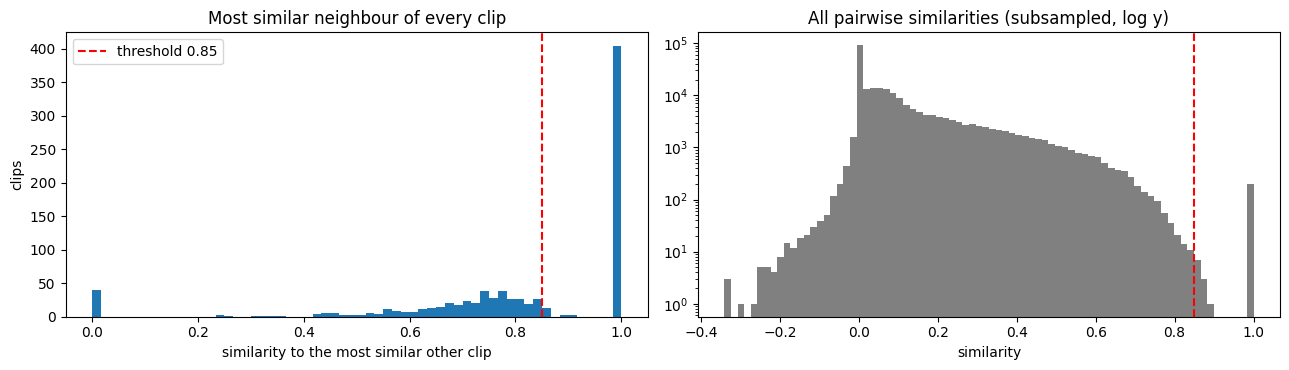

In [6]:
# ---- (c) detector validation on a control: a re-encoded copy of a REAL clip must be flagged, unrelated clips must not ----
def recompress(arr, quality=40, gain=1.05):
    out = []
    for f in arr:
        ok, buf = cv2.imencode(".jpg", cv2.cvtColor(f, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, quality])
        g = cv2.cvtColor(cv2.imdecode(buf, 1), cv2.COLOR_BGR2RGB).astype(np.float32) * gain
        out.append(np.clip(g, 0, 255).astype(np.uint8))
    return np.stack(out)

def clip_similarity(ra, rb):
    ra, rb = ra[None], rb[None]
    return max(float(shifted_sim(np.concatenate([ra, rb]), s)[0, 1]) for s in range(-MAX_SHIFT, MAX_SHIFT + 1))

k_ctrl = int(np.argmax(ENERGY))                           # a clip with plenty of motion
ctrl_sim = clip_similarity(RES[k_ctrl], residual_clip(recompress(np.load(CACHE_DIR / f"{IDS[k_ctrl]}.npy"))))
print(f"control: JPEG(q=40) + 5% brightness copy of clip {IDS[k_ctrl]} -> similarity {ctrl_sim:.3f} (threshold {DUP_SIM})")
print(f"         most similar *different* clip in the dataset      -> similarity {S[k_ctrl].max():.3f}")
print("detector sanity check:", "PASS" if S[k_ctrl].max() < DUP_SIM <= ctrl_sim else "CHECK THRESHOLD (see histogram below)")

# ---- (b4) collect all duplicate pairs ----
edges = {}
def add_edge(a, b, kind):
    a, b = int(min(a, b)), int(max(a, b))
    edges.setdefault((a, b), set()).add(kind)
for col_name, series in (("exact file (SHA-256)", hashes["sha256"].values), ("exact frames (MD5)", np.array(frame_md5))):
    for _, g in pd.Series(IDS).groupby(series):
        g = list(g)
        for x in range(len(g)):
            for y in range(x + 1, len(g)):
                add_edge(g[x], g[y], col_name)
ii, jj = np.where(np.triu(S >= DUP_SIM, k=1))
for a, b in zip(ii, jj):
    add_edge(IDS[a], IDS[b], "near-duplicate (motion residual)")
pos = {int(i): k for k, i in enumerate(IDS)}

lab   = meta.set_index("id")["label"]
spl   = week5_splits.set_index("id")["split"]
pairs = pd.DataFrame([dict(id_a=a, id_b=b, kind=" + ".join(sorted(k)), sim=float(S[pos[a], pos[b]]),
                           label_a=int(lab[a]), label_b=int(lab[b]), split_a=spl[a], split_b=spl[b])
                      for (a, b), k in edges.items()])
print(f"\nflagged duplicate pairs: {len(pairs)}")
if len(pairs):
    pairs["cross_split"] = pairs.split_a != pairs.split_b
    pairs["label_conflict"] = pairs.label_a != pairs.label_b
    print(pairs.sort_values("sim", ascending=False).head(15).round(4).to_string(index=False))
    print("\nby type:\n", pairs["kind"].value_counts().to_string())
    print(f"\npairs inside the same split : {(~pairs.cross_split).sum()}")
    print(f"pairs ACROSS splits (leakage): {pairs.cross_split.sum()}")
    print(f"pairs with conflicting labels: {pairs.label_conflict.sum()}  (same footage labelled differently would be a labelling error)")

best_sim = S.max(1)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(best_sim[np.isfinite(best_sim)], bins=60); ax[0].axvline(DUP_SIM, color="r", ls="--", label=f"threshold {DUP_SIM}")
ax[0].set_xlabel("similarity to the most similar other clip"); ax[0].set_ylabel("clips")
ax[0].set_title("Most similar neighbour of every clip"); ax[0].legend()
allsim = S[np.isfinite(S)]
ax[1].hist(allsim[::max(1, len(allsim) // 200000)], bins=80, color="gray"); ax[1].axvline(DUP_SIM, color="r", ls="--"); ax[1].set_yscale("log")
ax[1].set_title("All pairwise similarities (subsampled, log y)"); ax[1].set_xlabel("similarity")
plt.tight_layout(); plt.show()

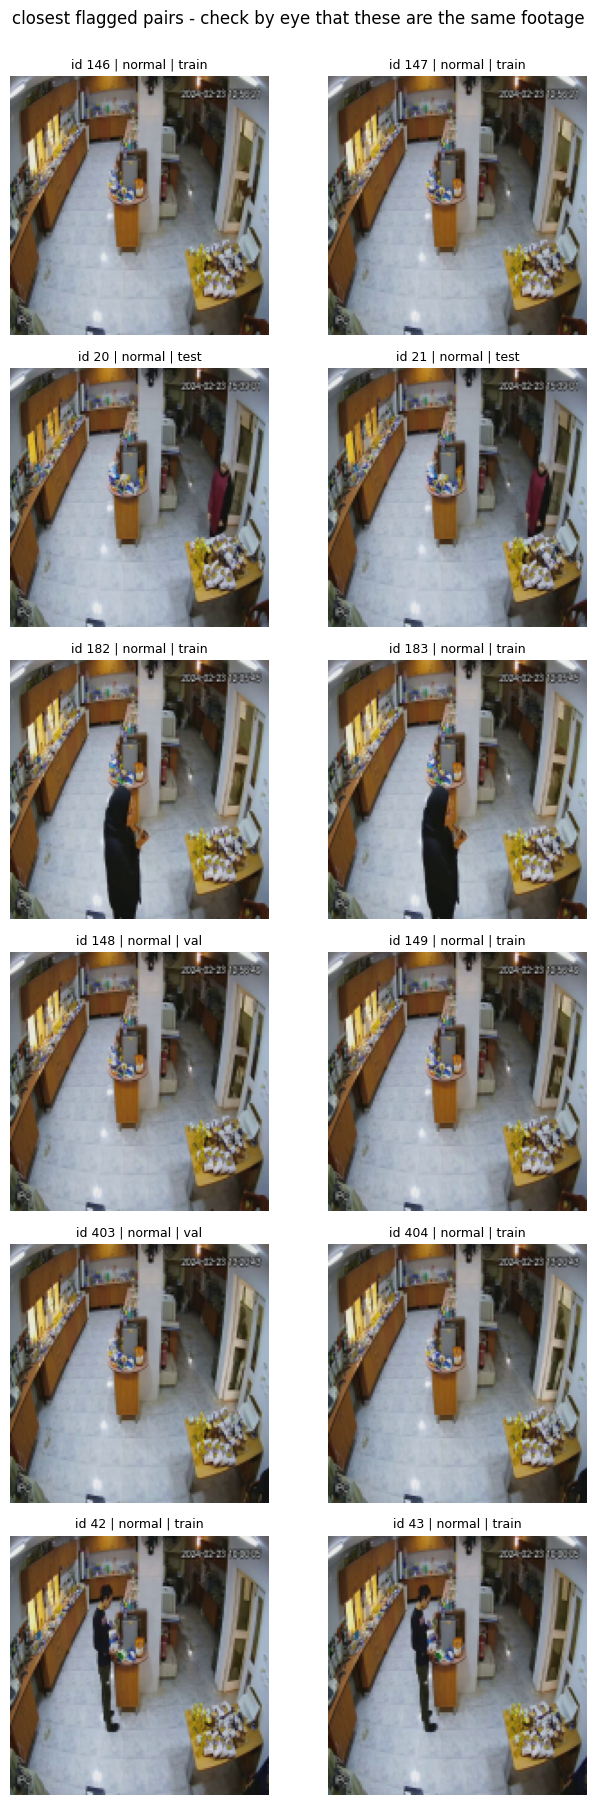

duplicate groups with >1 clip: 225 (covering 453 clips); largest group: 4

Week 5 split - clips belonging to a duplicate group that spans several splits:
 split
train    102
val       57
test      58
=> 58 of 129 Week 5 test clips share a duplicate group with train/val.


In [7]:
# ---- (e) visual inspection of the closest flagged pairs (middle sampled frame of both clips) ----
if len(pairs):
    show = pairs.sort_values("sim", ascending=False).head(6)
    fig, axes = plt.subplots(len(show), 2, figsize=(7, 3.0 * len(show)), squeeze=False)
    for r, row in enumerate(show.itertuples()):
        for c, vid in enumerate((row.id_a, row.id_b)):
            axes[r, c].imshow(np.load(CACHE_DIR / f"{vid}.npy")[NT // 2]); axes[r, c].axis("off")
            axes[r, c].set_title(f"id {vid} | {CLASS_NAMES[lab[vid]]} | {spl[vid]}", fontsize=9)
    plt.suptitle("closest flagged pairs - check by eye that these are the same footage", y=1.0); plt.tight_layout(); plt.show()
else:
    print("No flagged pairs -> nothing to inspect.")

# ---- groups = connected components of the duplicate graph ----
parent = {int(i): int(i) for i in IDS}
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
for (a, b) in edges:
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra
meta["group"] = [find(int(i)) for i in IDS]
gsize = meta.groupby("group").size()
print(f"duplicate groups with >1 clip: {(gsize > 1).sum()} (covering {gsize[gsize > 1].sum()} clips); largest group: {gsize.max()}")
if gsize.max() > max(10, 0.03 * len(meta)):
    print(f"WARNING: the largest group has {gsize.max()} clips ({gsize.max() / len(meta):.1%} of the data). That is more than a few re-uploads - "
          f"the detector is probably matching scene similarity. Inspect the pairs above and raise DUP_SIM before trusting the regrouped split.")

# ---- (c) how many validation / test clips have a duplicate in another split? ----
w5 = week5_splits.assign(group=meta["group"].values)
split_per_group = w5.groupby("group")["split"].nunique()
leaky_groups = split_per_group[split_per_group > 1].index
leak_table = (w5[w5.group.isin(leaky_groups)].groupby("split").size().reindex(["train", "val", "test"]).fillna(0).astype(int))
print("\nWeek 5 split - clips belonging to a duplicate group that spans several splits:\n", leak_table.to_string())
test_leaked = w5[(w5.split == "test") & w5.group.isin(leaky_groups)]
print(f"=> {len(test_leaked)} of {int((w5.split == 'test').sum())} Week 5 test clips share a duplicate group with train/val.")

In [8]:
# ---- (f) decision: keep the Week 5 split only if it is leak-free, otherwise rebuild it group-aware ----
if len(leaky_groups) == 0:
    SPLIT_TAG = "week5"
    final_splits = w5.copy()
    print("No duplicate group spans several splits -> the Week 5 split is leak-free and is kept unchanged.")
else:
    SPLIT_TAG = "grouped"
    sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=CFG["seed"])       # 7 folds -> ~14 % test, ~14 % val
    folds = [te for _, te in sgkf.split(meta, meta["label"], groups=meta["group"])]
    split_col = np.array(["train"] * len(meta), dtype=object)
    split_col[folds[0]] = "test"; split_col[folds[1]] = "val"
    final_splits = meta.assign(split=split_col)
    print(f"Leakage found -> split rebuilt with StratifiedGroupKFold; duplicates now stay together. "
          f"Both models are trained and evaluated on this new split (Week 5 numbers are NOT comparable any more).")
final_splits.to_csv(WORK_DIR / f"splits_final_{SPLIT_TAG}.csv", index=False)

# ---- final guarantees ----
assert final_splits.groupby("group")["split"].nunique().max() == 1, "a duplicate group spans several splits!"
assert final_splits.assign(sha=hashes["sha256"].values).groupby("sha")["split"].nunique().max() == 1, "identical files in several splits!"
assert final_splits["id"].is_unique
train_df, val_df, test_df = [final_splits[final_splits.split == s].reset_index(drop=True) for s in ("train", "val", "test")]
print("\nFINAL SPLIT:", SPLIT_TAG)
print(final_splits.groupby(["split", "label"]).size().unstack().rename(columns=dict(enumerate(CLASS_NAMES))))
print("leak check passed: no duplicate group and no identical file occurs in more than one split.")

CKPT_BASE = WORK_DIR / ("checkpoints_resnet18" if SPLIT_TAG == "week5" else f"checkpoints_resnet18_{SPLIT_TAG}")
CKPT_HF   = WORK_DIR / f"checkpoints_videomae_{SPLIT_TAG}"
CKPT_SCR  = WORK_DIR / f"checkpoints_resnet18_scratch_{SPLIT_TAG}"

Leakage found -> split rebuilt with StratifiedGroupKFold; duplicates now stay together. Both models are trained and evaluated on this new split (Week 5 numbers are NOT comparable any more).

FINAL SPLIT: grouped
label  normal  shoplifting
split                     
test       71           47
train     379          232
val        81           45
leak check passed: no duplicate group and no identical file occurs in more than one split.


## 6. How many frames? Study of T 

Temporal spacing between consecutive sampled frames:
  T  median_gap_s  shortest_clip_gap_s  longest_clip_gap_s  median_frames_between_samples
 4          3.25                 0.75               18.50                          81.25
 8          1.62                 0.38                9.25                          40.62
16          0.81                 0.19                4.62                          20.31
32          0.41                 0.09                2.31                          10.16
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 231MB/s]


ResNet18 features:   0%|          | 0/107 [00:00<?, ?it/s]


Cross-validated frozen-feature probe (train+val only):
     f1_mean  f1_std  auc_mean  auc_std  relative_cost_(tokens)
T                                                             
4    0.9782  0.0142    0.9989   0.0021                    0.25
8    0.9865  0.0142    0.9997   0.0007                    0.50
16   0.9942  0.0137    1.0000   0.0000                    1.00
32   0.9935  0.0102    0.9999   0.0002                    2.00


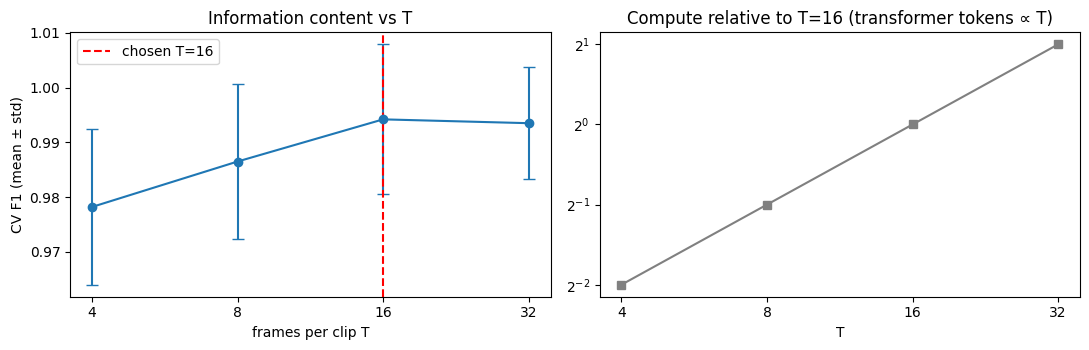


best T by mean CV F1: 16 (F1 0.9942 ± 0.0137)
T=16: F1 0.9942 ± 0.0137  | gap to best = +0.0000
=> T=16 is the best setting of the study.


In [9]:
# ---- 1. temporal coverage ----
rows = []
for T_try in STUDY_TS:
    rows.append(dict(T=T_try,
                     median_gap_s=float((meta.duration / T_try).median()),
                     shortest_clip_gap_s=float((meta.duration / T_try).min()),
                     longest_clip_gap_s=float((meta.duration / T_try).max()),
                     median_frames_between_samples=float((meta.n_frames / T_try).median())))
print("Temporal spacing between consecutive sampled frames:\n", pd.DataFrame(rows).round(2).to_string(index=False))

# ---- 2. frozen-feature probe ----
FEAT_PATH = WORK_DIR / "Tstudy_features.npy"
IMNET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMNET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def extract_study_features():
    if FEAT_PATH.exists():
        f = np.load(FEAT_PATH)
        if f.shape[0] == len(meta) and f.shape[1] == STUDY_TOTAL:
            return f
    net = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)   # must be ImageNet weights
    net.fc = nn.Identity(); net.eval().to(DEVICE)
    mean, std = IMNET_MEAN.to(DEVICE), IMNET_STD.to(DEVICE)
    feats = np.zeros((len(meta), STUDY_TOTAL, 512), np.float16)
    with torch.no_grad():
        for s in tqdm(range(0, len(meta), 8), desc="ResNet18 features"):
            ids_b = IDS[s:s + 8]
            x = torch.from_numpy(np.stack([np.load(STUDY_DIR / f"{i}.npy") for i in ids_b])).to(DEVICE)
            b, t = x.shape[:2]
            x = (x.flatten(0, 1).permute(0, 3, 1, 2).float() / 255 - mean) / std
            with torch.autocast(DEVICE.type, enabled=USE_AMP):
                f = net(x)
            feats[s:s + b] = f.float().view(b, t, -1).cpu().numpy()
    np.save(FEAT_PATH, feats)
    return feats

feats = extract_study_features()

def clip_descriptor(f):                          # f: (N, T, 512)
    return np.concatenate([f.mean(1), f.max(1), np.abs(np.diff(f, axis=1)).mean(1)], axis=1)

dev_mask = final_splits["split"].isin(["train", "val"]).to_numpy()          # the TEST set is never used here
y_dev, g_dev = final_splits["label"].to_numpy()[dev_mask], final_splits["group"].to_numpy()[dev_mask]
rows = []
for T_try in STUDY_TS:
    a, b = STUDY_OFFSETS[T_try]
    Xd = clip_descriptor(feats[dev_mask, a:b].astype(np.float32))
    for rep in range(3):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=rep)
        for k, (tr, te) in enumerate(cv.split(Xd, y_dev, g_dev)):
            clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=3000, class_weight="balanced"))
            clf.fit(Xd[tr], y_dev[tr]); p = clf.predict_proba(Xd[te])[:, 1]
            rows.append(dict(T=T_try, rep=rep, fold=k, f1=f1_score(y_dev[te], p >= 0.5), auc=roc_auc_score(y_dev[te], p)))
study = pd.DataFrame(rows)
summ = study.groupby("T").agg(f1_mean=("f1", "mean"), f1_std=("f1", "std"), auc_mean=("auc", "mean"), auc_std=("auc", "std")).round(4)
summ["relative_cost_(tokens)"] = summ.index / CFG["T"]
print("\nCross-validated frozen-feature probe (train+val only):\n", summ.to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].errorbar(summ.index, summ.f1_mean, yerr=summ.f1_std, marker="o", capsize=4); ax[0].set_xscale("log", base=2)
ax[0].axvline(CFG["T"], color="r", ls="--", label=f"chosen T={CFG['T']}"); ax[0].set_xticks(STUDY_TS); ax[0].set_xticklabels(STUDY_TS)
ax[0].set_xlabel("frames per clip T"); ax[0].set_ylabel("CV F1 (mean ± std)"); ax[0].legend(); ax[0].set_title("Information content vs T")
ax[1].plot(summ.index, summ["relative_cost_(tokens)"], marker="s", color="gray"); ax[1].set_xscale("log", base=2); ax[1].set_yscale("log", base=2)
ax[1].set_xticks(STUDY_TS); ax[1].set_xticklabels(STUDY_TS); ax[1].set_xlabel("T"); ax[1].set_title("Compute relative to T=16 (transformer tokens ∝ T)")
plt.tight_layout(); plt.show()

best_T = int(summ.f1_mean.idxmax()); best_row = summ.loc[best_T]; row16 = summ.loc[CFG["T"]]
print(f"\nbest T by mean CV F1: {best_T} (F1 {best_row.f1_mean:.4f} ± {best_row.f1_std:.4f})")
print(f"T={CFG['T']}: F1 {row16.f1_mean:.4f} ± {row16.f1_std:.4f}  | gap to best = {best_row.f1_mean - row16.f1_mean:+.4f}")
if best_T == CFG["T"]:
    print(f"=> T={CFG['T']} is the best setting of the study.")
elif row16.f1_mean >= best_row.f1_mean - best_row.f1_std:
    print(f"=> T={CFG['T']} is within one standard deviation of the best (T={best_T}) at {CFG['T'] / best_T:.2f}x its compute -> adequate.")
else:
    print(f"=> T={best_T} scores clearly higher in this probe (+{best_row.f1_mean - row16.f1_mean:.3f} F1) at {best_T / CFG['T']:.1f}x the tokens/compute. "
          f"T={CFG['T']} is kept because VideoMAE was pretrained with {CFG['T']} frames and the Week 5 baseline uses it; larger T is future work.")

## 7. pretrained video classifiers

In [10]:
from huggingface_hub import HfApi
from transformers import AutoConfig, AutoImageProcessor, VideoMAEForVideoClassification

api = HfApi()
try:
    try:
        found = list(api.list_models(pipeline_tag="video-classification", sort="downloads", direction=-1, limit=20))
    except TypeError:
        found = list(api.list_models(pipeline_tag="video-classification", sort="downloads", limit=20))
    top = pd.DataFrame([dict(model_id=m.id, downloads=getattr(m, "downloads", None), likes=getattr(m, "likes", None)) for m in found])
    print("Most downloaded video-classification models on the Hub:\n", top.to_string(index=False))
except Exception as e:
    print("Hub search failed (", type(e).__name__, str(e)[:100], ") - continuing with the shortlist below.")

SHORTLIST = ["MCG-NJU/videomae-base-finetuned-kinetics", "MCG-NJU/videomae-small-finetuned-kinetics",
             "facebook/timesformer-base-finetuned-k400"]
if CFG["hf_model"] not in SHORTLIST:
    SHORTLIST.insert(0, CFG["hf_model"])
rows = []
for name in SHORTLIST:
    row = dict(model_id=name, params_M=np.nan, downloads=np.nan, num_frames=np.nan, image_size=np.nan, pretrain_labels=np.nan)
    try:
        info = api.model_info(name)
        row["downloads"] = getattr(info, "downloads", np.nan)
        st = getattr(info, "safetensors", None)
        if st is not None and getattr(st, "total", None):
            row["params_M"] = round(st.total / 1e6, 1)
    except Exception as e:
        row["note"] = f"hub info: {type(e).__name__}"
    try:
        cfg = AutoConfig.from_pretrained(name)
        row.update(num_frames=getattr(cfg, "num_frames", np.nan), image_size=getattr(cfg, "image_size", np.nan),
                   pretrain_labels=len(getattr(cfg, "id2label", {}) or {}))
    except Exception as e:
        row["note"] = row.get("note", "") + f" config: {type(e).__name__}"
    rows.append(row)
print("\nShortlist:\n", pd.DataFrame(rows).to_string(index=False))
print(f"\nSELECTED: {CFG['hf_model']}")

Most downloaded video-classification models on the Hub:
                                          model_id  downloads  likes
                   facebook/vjepa2-vitl-fpc64-256     325582    217
                            MCG-NJU/videomae-base     301472     59
           microsoft/xclip-base-patch16-zero-shot     272146     35
         MCG-NJU/videomae-base-finetuned-kinetics     106501     52
                    microsoft/xclip-large-patch14      78768     23
                     microsoft/xclip-base-patch32      72040    126
                   facebook/vjepa2-vitg-fpc64-256      63382     62
                              google/vivit-b-16x2      51607     21
                  google/vivit-b-16x2-kinetics400      36773     47
        MCG-NJU/videomae-large-finetuned-kinetics      22625     13
              facebook/vjepa2-vitl-fpc16-256-ssv2      17927     19
           microsoft/xclip-base-patch32-16-frames      15819     11
         facebook/timesformer-base-finetuned-k400      1484

config.json:   0%|          | 0.00/22.9k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/22.9k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/22.7k [00:00<?, ?B/s]


Shortlist:
                                  model_id  params_M  downloads  num_frames  image_size  pretrain_labels
 MCG-NJU/videomae-base-finetuned-kinetics      86.5     106501          16         224              400
MCG-NJU/videomae-small-finetuned-kinetics       NaN       4126          16         224              400
 facebook/timesformer-base-finetuned-k400       NaN      14842           8         224              400

SELECTED: MCG-NJU/videomae-base-finetuned-kinetics


## 8. Load the pretrained model and adapt the classifier head to 2 classes

In [12]:
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file

MODEL_NAME = CFG["hf_model"]
ID2LABEL, LABEL2ID = {0: "normal", 1: "shoplifting"}, {"normal": 0, "shoplifting": 1}

orig_cfg = AutoConfig.from_pretrained(MODEL_NAME)
print(f"original checkpoint: {orig_cfg.architectures} | classes: {len(orig_cfg.id2label)} | frames: {orig_cfg.num_frames} | size: {orig_cfg.image_size}")

try:
    result = VideoMAEForVideoClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID, ignore_mismatched_sizes=True, output_loading_info=True)
    model_hf, loading_info = result
except Exception as e:
    print("loading with output_loading_info failed:", type(e).__name__, str(e)[:120], "-> retrying without it")
    model_hf = VideoMAEForVideoClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID, ignore_mismatched_sizes=True)
    loading_info = {}
MODEL_LOADED = True

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
HF_MEAN, HF_STD = list(processor.image_mean), list(processor.image_std)
NUM_FRAMES, IMG = model_hf.config.num_frames, model_hf.config.image_size
assert NUM_FRAMES == CFG["T"], f"model expects {NUM_FRAMES} frames but the pipeline samples {CFG['T']}"
assert IMG <= CFG["hf_cache_size"]

# ---- which tensors were NOT loaded from the checkpoint? only the new head may be; attention biases are a known layout difference ----
reinit = sorted({k for k in loading_info.get("missing_keys", [])} | {m[0] for m in loading_info.get("mismatched_keys", [])})
ATTN_BIAS = ("attention.attention.query.bias", "attention.attention.key.bias", "attention.attention.value.bias")
unexpected = [k for k in reinit if not k.startswith("classifier") and not k.endswith(ATTN_BIAS)]
assert not unexpected, f"unexpected re-initialised weights: {unexpected}"

# ---- checkpoint stores q_bias / v_bias (no key bias); this transformers version has query/key/value .bias -> copy them over ----
sd = load_file(hf_hub_download(MODEL_NAME, "model.safetensors"))
with torch.no_grad():
    for i in range(model_hf.config.num_hidden_layers):
        att = model_hf.videomae.encoder.layer[i].attention.attention
        pre = f"videomae.encoder.layer.{i}.attention.attention."
        if pre + "q_bias" in sd:                      # skipped automatically if the library already loaded them
            att.query.bias.copy_(sd[pre + "q_bias"])
            att.value.bias.copy_(sd[pre + "v_bias"])
            att.key.bias.zero_()                      # original VideoMAE has no key bias (fixed at 0)
for i in range(model_hf.config.num_hidden_layers):
    pre = f"videomae.encoder.layer.{i}.attention.attention."
    if pre + "q_bias" in sd:
        att = model_hf.videomae.encoder.layer[i].attention.attention
        assert torch.equal(att.query.bias, sd[pre + "q_bias"].to(att.query.bias.dtype))
        assert torch.equal(att.value.bias, sd[pre + "v_bias"].to(att.value.bias.dtype))
print("attention q/v biases restored from the checkpoint; the only newly initialised weights are the classifier head.")

head = model_hf.classifier
assert isinstance(head, nn.Linear) and head.in_features == model_hf.config.hidden_size and head.out_features == 2, head
assert model_hf.config.num_labels == 2 and model_hf.config.id2label == ID2LABEL
HEAD_OK = True
n_total = sum(p.numel() for p in model_hf.parameters())
print(f"classifier head: {head}  (was Linear(768, {len(orig_cfg.id2label)}))")
print(f"id2label: {model_hf.config.id2label} | parameters: {n_total / 1e6:.1f} M | input: (B, {NUM_FRAMES}, 3, {IMG}, {IMG}) | normalisation mean={HF_MEAN} std={HF_STD}")

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `400`.


original checkpoint: ['VideoMAEForVideoClassification'] | classes: 400 | frames: 16 | size: 224


Loading weights:   0%|          | 0/162 [00:00<?, ?it/s]

[transformers] VideoMAEForVideoClassification LOAD REPORT from: MCG-NJU/videomae-base-finetuned-kinetics
Key                                                            | Status     |                                                                                         
---------------------------------------------------------------+------------+-----------------------------------------------------------------------------------------
videomae.encoder.layer.{0...11}.attention.attention.v_bias     | UNEXPECTED |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.q_bias     | UNEXPECTED |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.key.bias   | MISSING    |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.value.bi

attention q/v biases restored from the checkpoint; the only newly initialised weights are the classifier head.
classifier head: Linear(in_features=768, out_features=2, bias=True)  (was Linear(768, 400))
id2label: {0: 'normal', 1: 'shoplifting'} | parameters: 86.2 M | input: (B, 16, 3, 224, 224) | normalisation mean=[0.485, 0.456, 0.406] std=[0.229, 0.224, 0.225]


## 9. Data pipeline: Week 5 augmentation and dataset, re-used

train:  611 clips, tensor shape (16, 3, 224, 224) (T, C, H, W)
val  :  126 clips, tensor shape (16, 3, 224, 224) (T, C, H, W)
test :  118 clips, tensor shape (16, 3, 224, 224) (T, C, H, W)
Augmentation verified: identical parameters for all frames of a clip.


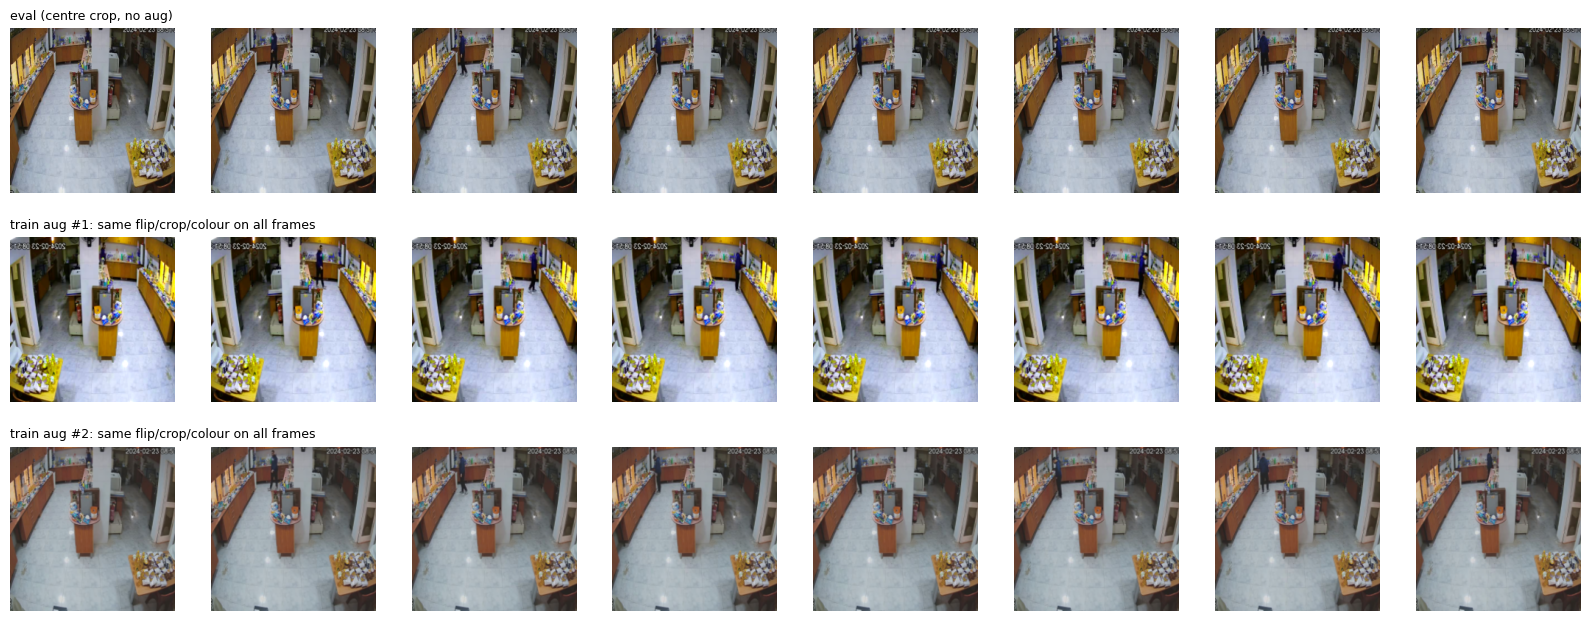

forward check on a real validation batch -> logits (8, 2) (2 classes)


In [13]:
class ClipAugment:
    def __init__(self, out_size=112, train=True, mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225),
                 scale=(0.6, 1.0), ratio=(0.85, 1.18), flip_p=0.5, brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05):
        self.out_size, self.train, self.scale, self.ratio = out_size, train, scale, ratio
        self.flip_p, self.bri, self.con, self.sat, self.hue = flip_p, brightness, contrast, saturation, hue
        self.mean = torch.tensor(mean).view(1, 3, 1, 1); self.std = torch.tensor(std).view(1, 3, 1, 1)

    def sample_params(self, H, W):
        area = H * W * random.uniform(*self.scale)
        r = math.exp(random.uniform(math.log(self.ratio[0]), math.log(self.ratio[1])))
        w = min(W, int(round(math.sqrt(area * r)))); h = min(H, int(round(math.sqrt(area / r))))
        return dict(top=random.randint(0, H - h), left=random.randint(0, W - w), h=h, w=w,
                    flip=random.random() < self.flip_p,
                    bri=random.uniform(1 - self.bri, 1 + self.bri), con=random.uniform(1 - self.con, 1 + self.con),
                    sat=random.uniform(1 - self.sat, 1 + self.sat), hue=random.uniform(-self.hue, self.hue))

    def apply(self, x, p):
        x = TF.resized_crop(x, p["top"], p["left"], p["h"], p["w"], [self.out_size, self.out_size], antialias=True)
        if p["flip"]:
            x = TF.horizontal_flip(x)
        x = TF.adjust_brightness(x, p["bri"]); x = TF.adjust_contrast(x, p["con"])
        x = TF.adjust_saturation(x, p["sat"]);  x = TF.adjust_hue(x, p["hue"])
        return x.clamp(0, 1)

    def __call__(self, clip_uint8, params=None):
        x = clip_uint8.float() / 255.0
        T, C, H, W = x.shape
        if self.train:
            x = self.apply(x, params or self.sample_params(H, W))
        else:
            s = int(round(H * 0.875)) if H > self.out_size else H
            x = TF.resized_crop(x, (H - s) // 2, (W - s) // 2, s, s, [self.out_size, self.out_size], antialias=True)
        return (x - self.mean) / self.std

class ShopliftingDataset(Dataset):
    """Loads cached frames of one video and returns (clip[T,C,H,W] float32, label)."""
    def __init__(self, df, cache_dir, transform):
        self.ids, self.labels = df["id"].tolist(), df["label"].tolist()
        self.cache_dir, self.transform = Path(cache_dir), transform
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        arr = np.load(self.cache_dir / f"{self.ids[i]}.npy")                 # (T, H, W, 3) uint8
        clip = torch.from_numpy(arr).permute(0, 3, 1, 2).contiguous()        # (T, C, H, W)
        return self.transform(clip), torch.tensor(self.labels[i], dtype=torch.float32)

def make_loader(ds, batch_size, shuffle):
    nw = CFG["num_workers"]
    return DataLoader(ds, batch_size, shuffle=shuffle, num_workers=nw, pin_memory=DEVICE.type == "cuda",
                      drop_last=shuffle and len(ds) > batch_size, persistent_workers=shuffle and nw > 0)

# ---- VideoMAE datasets: 256 px cache -> 224 px crop, normalisation from the model's own processor ----
hf_aug_train = ClipAugment(IMG, True,  HF_MEAN, HF_STD)
hf_aug_eval  = ClipAugment(IMG, False, HF_MEAN, HF_STD)
hf_train_ds = ShopliftingDataset(train_df, HF_CACHE_DIR, hf_aug_train)
hf_val_ds   = ShopliftingDataset(val_df,   HF_CACHE_DIR, hf_aug_eval)
hf_test_ds  = ShopliftingDataset(test_df,  HF_CACHE_DIR, hf_aug_eval)
hf_train_loader = make_loader(hf_train_ds, CFG["hf_batch"], True)
hf_val_loader   = make_loader(hf_val_ds,   CFG["hf_batch"] * 2, False)
hf_test_loader  = make_loader(hf_test_ds,  CFG["hf_batch"] * 2, False)

expected = (CFG["T"], 3, IMG, IMG)
for name, ds in [("train", hf_train_ds), ("val", hf_val_ds), ("test", hf_test_ds)]:
    shapes = {tuple(ds[i][0].shape) for i in range(min(len(ds), 10))}
    assert shapes == {expected}, shapes
    print(f"{name:5s}: {len(ds):4d} clips, tensor shape {expected} (T, C, H, W)")

# ---- Week 5 check: augmentation parameters are identical for all frames of a clip ----
clip = torch.from_numpy(np.load(HF_CACHE_DIR / f"{train_df.id[0]}.npy")).permute(0, 3, 1, 2).contiguous()
p = hf_aug_train.sample_params(*clip.shape[-2:])
whole = hf_aug_train(clip, params=p)
per_frame = torch.cat([hf_aug_train(clip[t:t + 1], params=p) for t in range(clip.shape[0])])
assert torch.allclose(whole, per_frame, atol=1e-5), "augmentation differs between frames!"
out = hf_aug_train(clip[:1].repeat(clip.shape[0], 1, 1, 1))
assert all(torch.allclose(out[0], out[t], atol=1e-5) for t in range(1, out.shape[0]))
print("Augmentation verified: identical parameters for all frames of a clip.")

def show_clip(x, ax_row, title, mean=HF_MEAN, std=HF_STD):
    x = (x * torch.tensor(std).view(1, 3, 1, 1) + torch.tensor(mean).view(1, 3, 1, 1)).clamp(0, 1)
    for k, a in enumerate(ax_row):
        a.imshow(x[k * (x.shape[0] // len(ax_row))].permute(1, 2, 0)); a.axis("off")
    ax_row[0].set_title(title, loc="left", fontsize=9)
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
show_clip(hf_aug_eval(clip), axes[0], "eval (centre crop, no aug)")
for r in (1, 2):
    show_clip(hf_aug_train(clip), axes[r], f"train aug #{r}: same flip/crop/colour on all frames")
plt.tight_layout(); plt.show()

# ---- forward check of the adapted model on a REAL batch ----
xb, yb = next(iter(hf_val_loader))
model_hf.to(DEVICE).eval()
with torch.no_grad(), torch.autocast(DEVICE.type, enabled=USE_AMP):
    logits = model_hf(pixel_values=xb.to(DEVICE)).logits
assert logits.shape == (xb.shape[0], 2), logits.shape
print("forward check on a real validation batch -> logits", tuple(logits.shape), "(2 classes)")

## 10. Fine-tuning

In [14]:
def save_checkpoint(path, **state):
    tmp = Path(str(path) + ".tmp")
    torch.save(state, tmp); os.replace(tmp, path)

def tune_threshold(probs, labels):
    """Threshold maximising F1 on the VALIDATION set. If F1 is flat over a range, the middle of that range is used
    (more robust than the lowest threshold of the plateau)."""
    grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
    f1s = np.array([f1_score(labels, (probs >= t).astype(int), zero_division=0) for t in grid])
    best = grid[f1s >= f1s.max() - 1e-12]
    return float(best[np.argmin(np.abs(best - np.median(best)))])

def metrics_at(probs, labels, thr=0.5):
    pred = (probs >= thr).astype(int)
    return dict(accuracy=accuracy_score(labels, pred), precision=precision_score(labels, pred, zero_division=0),
                recall=recall_score(labels, pred, zero_division=0), f1=f1_score(labels, pred, zero_division=0))

@torch.no_grad()
def predict(model, loader, forward, to_prob, loss_fn=None, tta=False):
    """Returns (loss, P(shoplifting), labels). tta=True averages the logits of the clip and its horizontal flip."""
    model.eval(); losses, probs, labels = [], [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=USE_AMP):
            out = forward(model, x).float()
            if tta:
                out = (out + forward(model, x.flip(-1)).float()) / 2
        if loss_fn is not None:
            losses.append(loss_fn(out, y).item() * len(y))
        probs.append(to_prob(out).cpu()); labels.append(y.cpu())
    probs, labels = torch.cat(probs).numpy(), torch.cat(labels).numpy().astype(int)
    return (sum(losses) / len(labels) if losses else float("nan")), probs, labels

def fit_model(tag, model, forward, loss_fn, to_prob, train_loader, val_loader, make_opt, epochs, patience, ckpt_dir, accum=1):
    ckpt_dir.mkdir(parents=True, exist_ok=True)
    last_p, best_p = ckpt_dir / "last.pt", ckpt_dir / "best.pt"
    steps_per_epoch = math.ceil(len(train_loader) / accum)
    optimizer, scheduler = make_opt(model, steps_per_epoch, epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    history, start, best_f1, best_loss, bad = [], 0, -1.0, float("inf"), 0
    if last_p.exists():                                                   # ---- resume ----
        ck = torch.load(last_p, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
        scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
        history, start, best_f1, bad = ck["history"], ck["epoch"] + 1, ck["best_f1"], ck["bad_epochs"]
        best_loss = ck.get("best_loss", float("inf"))
        print(f"[{tag}] resumed from epoch {start} (best val F1 so far: {best_f1:.4f})")
    else:
        print(f"[{tag}] no checkpoint found -> training from the start.")
    for epoch in range(start, epochs):
        if bad >= patience:
            print(f"[{tag}] early stopping (patience {patience})."); break
        model.train(); t0, run, n = time.time(), 0.0, 0
        optimizer.zero_grad(set_to_none=True)
        for it, (x, y) in enumerate(tqdm(train_loader, desc=f"{tag} epoch {epoch + 1}/{epochs}", leave=False)):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            with torch.autocast(DEVICE.type, enabled=USE_AMP):
                loss = loss_fn(forward(model, x).float(), y)
            scaler.scale(loss / accum).backward()
            if (it + 1) % accum == 0 or it + 1 == len(train_loader):
                scaler.unscale_(optimizer); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True); scheduler.step()
            run += loss.item() * len(y); n += len(y)
        val_loss, vp, vl = predict(model, val_loader, forward, to_prob, loss_fn)
        m = metrics_at(vp, vl)
        history.append(dict(epoch=epoch + 1, train_loss=run / n, val_loss=val_loss, sec=time.time() - t0,
                            **{f"val_{k}": v for k, v in m.items()}))
        improved = (m["f1"] > best_f1 + 1e-9) or (abs(m["f1"] - best_f1) <= 1e-9 and val_loss < best_loss)
        if improved:
            best_f1, best_loss, bad = m["f1"], val_loss, 0
            save_checkpoint(best_p, model=model.state_dict(), epoch=epoch, val_f1=best_f1)
        else:
            bad += 1
        save_checkpoint(last_p, model=model.state_dict(), optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(),
                        scaler=scaler.state_dict(), epoch=epoch, history=history, best_f1=best_f1, best_loss=best_loss, bad_epochs=bad)
        print(f"[{tag}] epoch {epoch + 1:3d} | train {run / n:.4f} | val {val_loss:.4f} | acc {m['accuracy']:.3f} "
              f"| P {m['precision']:.3f} | R {m['recall']:.3f} | F1 {m['f1']:.3f} {'*' if improved else ''} | {time.time() - t0:.0f}s")
    return pd.DataFrame(history)

def load_best(model, ckpt_dir):
    best = torch.load(ckpt_dir / "best.pt", map_location=DEVICE, weights_only=False)
    model.load_state_dict(best["model"])
    return best

def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val"); ax[0].set_title(f"{title}: loss"); ax[0].legend(); ax[0].set_xlabel("epoch")
    ax[1].plot(h.epoch, h.val_accuracy, label="accuracy"); ax[1].plot(h.epoch, h.val_f1, label="F1"); ax[1].set_title(f"{title}: validation metrics"); ax[1].legend(); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.show()

In [15]:
# ---- VideoMAE: loss, forward, optimiser (layer-wise LR decay) ----
n_pos = int(train_df.label.sum()); n_neg = len(train_df) - n_pos
cls_weight = torch.tensor([len(train_df) / (2 * n_neg), len(train_df) / (2 * n_pos)], dtype=torch.float32, device=DEVICE)
print(f"train clips: {len(train_df)} (normal {n_neg}, shoplifting {n_pos}) | CE class weights: {cls_weight.cpu().numpy().round(3)}")

hf_forward = lambda m, x: m(pixel_values=x).logits
hf_loss    = lambda out, y: F.cross_entropy(out.float(), y.long(), weight=cls_weight)
hf_to_prob = lambda out: torch.softmax(out.float(), dim=-1)[:, 1]

def hf_param_groups(model, base_lr, decay, head_lr, wd):
    L = model.config.num_hidden_layers
    buckets = {}
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if name.startswith("classifier"):
            lid, lr = L + 2, head_lr
        else:
            m = re.match(r"videomae\.encoder\.layer\.(\d+)\.", name)
            lid = int(m.group(1)) + 1 if m else (0 if name.startswith("videomae.embeddings") else L + 1)
            lr = base_lr * decay ** (L + 1 - lid)
        no_wd = p.ndim == 1 or name.endswith(".bias")
        buckets.setdefault((lid, no_wd), dict(params=[], lr=lr, weight_decay=0.0 if no_wd else wd))["params"].append(p)
    return list(buckets.values())

def make_hf_opt(model, steps_per_epoch, epochs):
    opt = torch.optim.AdamW(hf_param_groups(model, CFG["hf_lr"], CFG["hf_layer_decay"], CFG["hf_head_lr"], CFG["hf_wd"]))
    total, warm = steps_per_epoch * epochs, max(1, steps_per_epoch * CFG["hf_warmup_epochs"])
    def lr_lambda(step):
        if step < warm:
            return (step + 1) / warm
        prog = (step - warm) / max(1, total - warm)
        return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * prog))
    return opt, torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)

if DEVICE.type == "cuda" and (torch.cuda.get_device_properties(0).total_memory / 2**30 < 12 or os.environ.get("GRAD_CKPT") == "1"):
    model_hf.gradient_checkpointing_enable(); print("gradient checkpointing enabled (small GPU)")

groups = hf_param_groups(model_hf, CFG["hf_lr"], CFG["hf_layer_decay"], CFG["hf_head_lr"], CFG["hf_wd"])
print("optimiser parameter groups (lr):", sorted({round(g["lr"], 8) for g in groups}))

model_hf.to(DEVICE)
hf_history = fit_model("VideoMAE", model_hf, hf_forward, hf_loss, hf_to_prob, hf_train_loader, hf_val_loader, make_hf_opt,
                       CFG["hf_epochs"], CFG["hf_patience"], CKPT_HF, accum=CFG["hf_accum"])
if len(hf_history):
    hf_history.to_csv(WORK_DIR / f"history_videomae_{SPLIT_TAG}.csv", index=False)

train clips: 611 (normal 379, shoplifting 232) | CE class weights: [0.806 1.317]
optimiser parameter groups (lr): [2.75e-06, 3.44e-06, 4.29e-06, 5.37e-06, 6.71e-06, 8.39e-06, 1.049e-05, 1.311e-05, 1.638e-05, 2.048e-05, 2.56e-05, 3.2e-05, 4e-05, 5e-05, 0.0005]
[VideoMAE] no checkpoint found -> training from the start.


VideoMAE epoch 1/12:   0%|          | 0/152 [00:00<?, ?it/s]

[VideoMAE] epoch   1 | train 0.6098 | val 0.6265 | acc 0.698 | P 0.544 | R 0.956 | F1 0.694 * | 66s


VideoMAE epoch 2/12:   0%|          | 0/152 [00:00<?, ?it/s]

[VideoMAE] epoch   2 | train 0.3679 | val 0.4052 | acc 0.865 | P 0.759 | R 0.911 | F1 0.828 * | 69s


...

[VideoMAE] epoch  10 | train 0.0297 | val 0.4381 | acc 0.881 | P 0.895 | R 0.756 | F1 0.819  | 66s


VideoMAE epoch 11/12:   0%|          | 0/152 [00:00<?, ?it/s]

[VideoMAE] epoch  11 | train 0.0108 | val 0.3462 | acc 0.913 | P 0.905 | R 0.844 | F1 0.874  | 66s


VideoMAE epoch 12/12:   0%|          | 0/152 [00:00<?, ?it/s]

[VideoMAE] epoch  12 | train 0.0246 | val 0.3182 | acc 0.929 | P 0.909 | R 0.889 | F1 0.899  | 66s


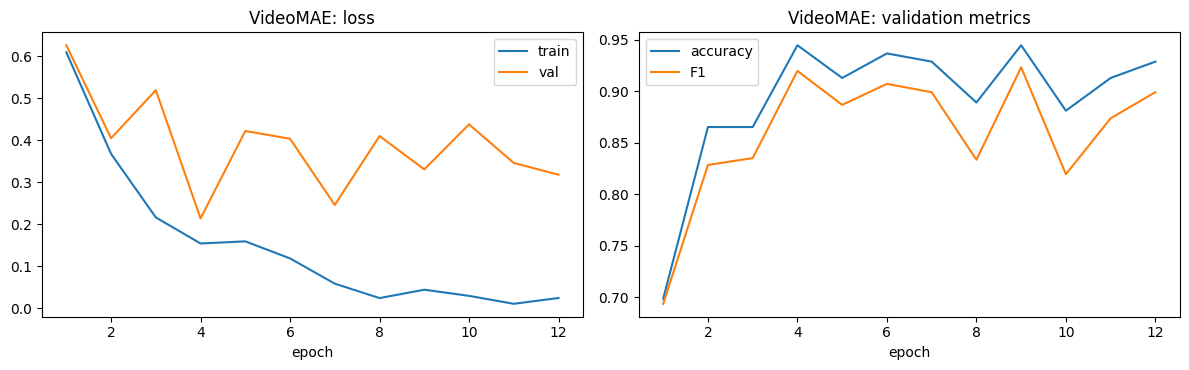

best VideoMAE epoch: 9 (val F1 0.9231)


In [16]:
plot_history(hf_history, "VideoMAE")
best_hf = load_best(model_hf, CKPT_HF)
print(f"best VideoMAE epoch: {best_hf['epoch'] + 1} (val F1 {best_hf['val_f1']:.4f})")

## 11. Evaluation 
1. Load the best checkpoint (selected on **validation** F1).
2. Predictions average the clip and its horizontally flipped copy (test-time augmentation, as in Week 5).
3. The decision threshold is tuned **on the validation set only** and then applied to the test set. Results at the untuned threshold 0.5 are reported next to it, because they involve no tuning at all.
4. The test set is used exactly once per model. 95 % confidence intervals come from a paired bootstrap over the test clips.


===== VideoMAE (fine-tuned): TEST SET (118 clips) =====
                     accuracy  precision  recall      f1
threshold 0.50         0.9915        1.0  0.9787  0.9892
tuned on val (0.28)    0.9915        1.0  0.9787  0.9892
ROC-AUC: 1.0000
              precision    recall  f1-score   support

      normal       0.99      1.00      0.99        71
 shoplifting       1.00      0.98      0.99        47

    accuracy                           0.99       118
   macro avg       0.99      0.99      0.99       118
weighted avg       0.99      0.99      0.99       118



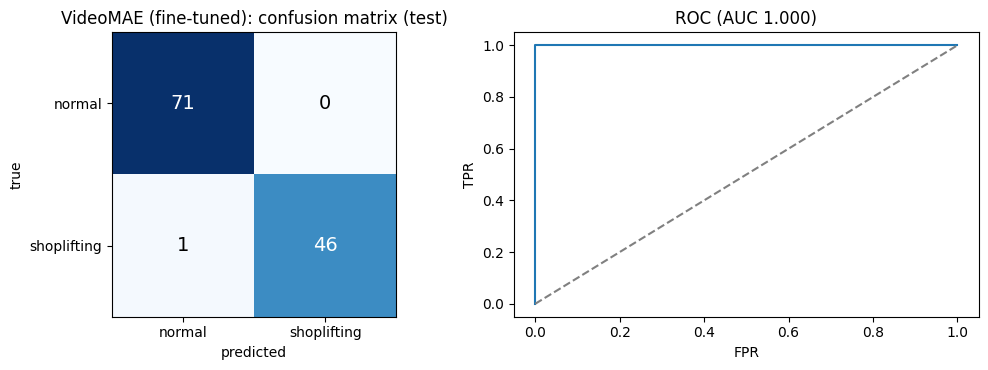

In [18]:
def evaluate_model(tag, model, forward, loss_fn, to_prob, val_loader, test_loader):
    _, vp, vl = predict(model, val_loader, forward, to_prob, loss_fn, tta=True)
    thr = tune_threshold(vp, vl)
    _, tp, tl = predict(model, test_loader, forward, to_prob, loss_fn, tta=True)
    res = pd.DataFrame({"threshold 0.50": metrics_at(tp, tl, 0.5), f"tuned on val ({thr:.2f})": metrics_at(tp, tl, thr)}).T
    auc = roc_auc_score(tl, tp) if len(set(tl)) > 1 else float("nan")
    print(f"\n===== {tag}: TEST SET ({len(tl)} clips) =====")
    print(res.round(4).to_string()); print(f"ROC-AUC: {auc:.4f}")
    print(classification_report(tl, (tp >= thr).astype(int), target_names=CLASS_NAMES, zero_division=0))
    return dict(tag=tag, thr=thr, probs=tp, labels=tl, results=res, auc=auc, val_probs=vp, val_labels=vl)

def plot_eval(ev):
    cm = confusion_matrix(ev["labels"], (ev["probs"] >= ev["thr"]).astype(int), labels=[0, 1])
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
    ax[0].imshow(cm, cmap="Blues"); ax[0].set_xticks([0, 1]); ax[0].set_yticks([0, 1])
    ax[0].set_xticklabels(CLASS_NAMES); ax[0].set_yticklabels(CLASS_NAMES); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true")
    ax[0].set_title(f"{ev['tag']}: confusion matrix (test)")
    for i in range(2):
        for j in range(2):
            ax[0].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
    fpr, tpr, _ = roc_curve(ev["labels"], ev["probs"]); ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], "--", c="gray")
    ax[1].set_title(f"ROC (AUC {ev['auc']:.3f})"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR")
    plt.tight_layout(); plt.show()

EV_HF = evaluate_model("VideoMAE (fine-tuned)", model_hf, hf_forward, hf_loss, hf_to_prob, hf_val_loader, hf_test_loader)
plot_eval(EV_HF)

## 12. The Week 5 model, evaluated on the same split

Split was rebuilt after the leakage audit -> the Week 5 model is retrained on the new split with the Week 5 recipe.
[Week5 CNN-BiGRU] no checkpoint found -> training from the start.


Week5 CNN-BiGRU epoch 1/30:   0%|          | 0/38 [00:00<?, ?it/s]

[Week5 CNN-BiGRU] epoch   1 | train 0.8657 | val 0.8481 | acc 0.643 | P 0.000 | R 0.000 | F1 0.000 * | 16s


Week5 CNN-BiGRU epoch 2/30:   0%|          | 0/38 [00:00<?, ?it/s]

[Week5 CNN-BiGRU] epoch   2 | train 0.8548 | val 0.8331 | acc 0.659 | P 0.571 | R 0.178 | F1 0.271 * | 15s


...

[Week5 CNN-BiGRU] epoch  28 | train 0.0973 | val 0.0489 | acc 0.992 | P 1.000 | R 0.978 | F1 0.989  | 15s


Week5 CNN-BiGRU epoch 29/30:   0%|          | 0/38 [00:00<?, ?it/s]

[Week5 CNN-BiGRU] epoch  29 | train 0.0740 | val 0.0443 | acc 0.992 | P 1.000 | R 0.978 | F1 0.989  | 15s


Week5 CNN-BiGRU epoch 30/30:   0%|          | 0/38 [00:00<?, ?it/s]

[Week5 CNN-BiGRU] epoch  30 | train 0.1339 | val 0.0466 | acc 0.992 | P 1.000 | R 0.978 | F1 0.989  | 15s
[Week5 CNN-BiGRU] best epoch 26 (val F1 0.9888)


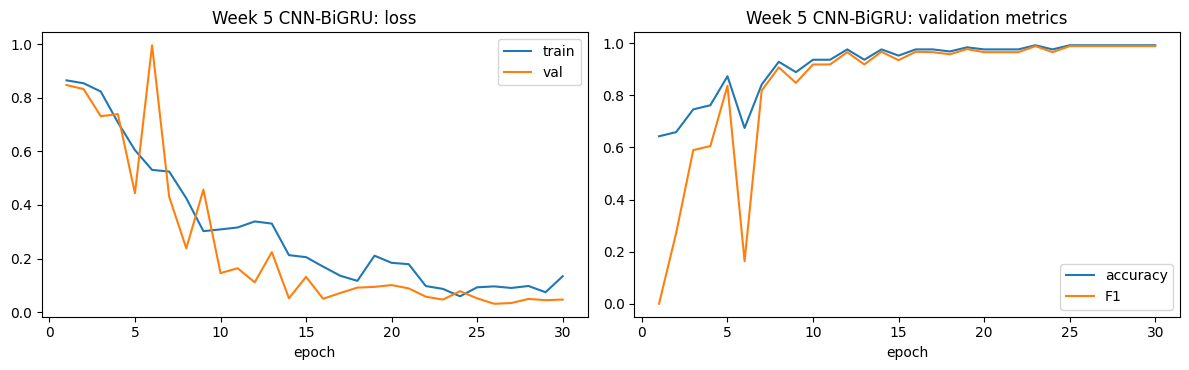


===== Week 5 CNN-BiGRU: TEST SET (118 clips) =====
                     accuracy  precision  recall      f1
threshold 0.50         0.9661        1.0  0.9149  0.9556
tuned on val (0.15)    0.9661        1.0  0.9149  0.9556
ROC-AUC: 1.0000
              precision    recall  f1-score   support

      normal       0.95      1.00      0.97        71
 shoplifting       1.00      0.91      0.96        47

    accuracy                           0.97       118
   macro avg       0.97      0.96      0.96       118
weighted avg       0.97      0.97      0.97       118



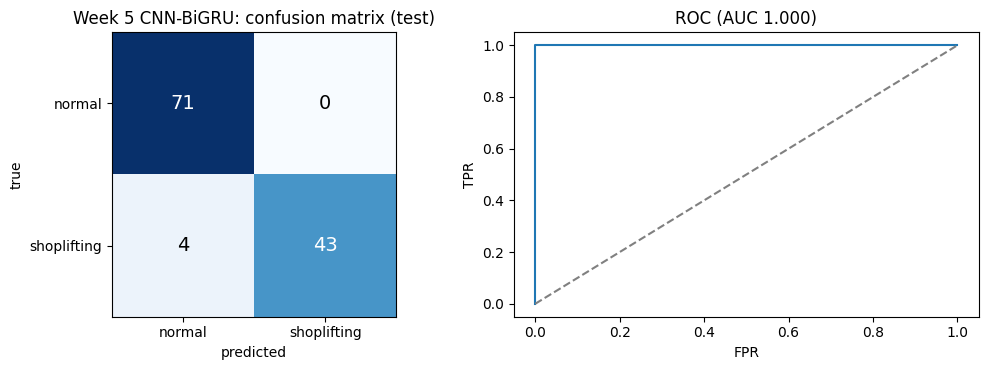

In [19]:
class FrameEncoder(nn.Module):
    """ImageNet-pretrained ResNet18 -> 512-d feature per frame."""
    def __init__(self, pretrained=True, freeze_early=True):
        super().__init__()
        try:
            weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
            net = torchvision.models.resnet18(weights=weights)
        except Exception as e:
            print("!!! WARNING: could not load ImageNet weights (" + str(e)[:80] + "). Enable Internet, otherwise results will be poor.")
            net = torchvision.models.resnet18(weights=None)
        self.stem = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool)
        self.layer1, self.layer2, self.layer3, self.layer4 = net.layer1, net.layer2, net.layer3, net.layer4
        self.out_dim = 512
        self.frozen = [self.stem, self.layer1] if freeze_early else []
        for m in self.frozen:
            for p in m.parameters():
                p.requires_grad = False
    def train(self, mode=True):
        super().train(mode)
        for m in self.frozen:
            m.eval()
        return self
    def forward(self, x):
        x = self.layer4(self.layer3(self.layer2(self.layer1(self.stem(x)))))
        return F.adaptive_avg_pool2d(x, 1).flatten(1)

class CNNBiGRU(nn.Module):
    def __init__(self, hidden=128, layers=2, dropout=0.5, pretrained=True):
        super().__init__()
        self.encoder = FrameEncoder(pretrained=pretrained)
        self.feat_drop = nn.Dropout(0.3)
        self.gru = nn.GRU(self.encoder.out_dim, hidden, layers, batch_first=True, bidirectional=True,
                          dropout=dropout if layers > 1 else 0.0)
        self.attn = nn.Linear(2 * hidden, 1)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * hidden, 64), nn.ReLU(inplace=True),
                                  nn.Dropout(dropout), nn.Linear(64, 1))
    def forward(self, x, return_attention=False):                 # x: (B, T, C, H, W)
        B, T = x.shape[:2]
        feats = self.feat_drop(self.encoder(x.flatten(0, 1))).view(B, T, -1)
        seq, _ = self.gru(feats)
        w = torch.softmax(self.attn(seq), dim=1)
        logit = self.head((w * seq).sum(1)).squeeze(1)
        return (logit, w.squeeze(-1)) if return_attention else logit

def make_base_opt(model, steps_per_epoch, epochs):
    backbone = [p for p in model.encoder.parameters() if p.requires_grad]
    head = [p for n, p in model.named_parameters() if not n.startswith("encoder.") and p.requires_grad]
    opt = torch.optim.AdamW([dict(params=backbone, lr=CFG["backbone_lr"]), dict(params=head, lr=CFG["head_lr"])], weight_decay=CFG["weight_decay"])
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[CFG["backbone_lr"], CFG["head_lr"]], epochs=epochs,
                                              steps_per_epoch=steps_per_epoch, pct_start=0.2)
    return opt, sch

base_pos_weight = torch.tensor([n_neg / max(n_pos, 1)], device=DEVICE)
base_forward = lambda m, x: m(x)
base_loss    = lambda out, y: F.binary_cross_entropy_with_logits(out.float(), y.float(), pos_weight=base_pos_weight)
base_to_prob = lambda out: torch.sigmoid(out.float())

base_train_ds = ShopliftingDataset(train_df, CACHE_DIR, ClipAugment(CFG["img_size"], True))
base_val_ds   = ShopliftingDataset(val_df,   CACHE_DIR, ClipAugment(CFG["img_size"], False))
base_test_ds  = ShopliftingDataset(test_df,  CACHE_DIR, ClipAugment(CFG["img_size"], False))
base_train_loader = make_loader(base_train_ds, CFG["base_batch"], True)
base_val_loader   = make_loader(base_val_ds,   CFG["base_batch"], False)
base_test_loader  = make_loader(base_test_ds,  CFG["base_batch"], False)

def run_baseline(tag, pretrained, ckpt_dir):
    m = CNNBiGRU(pretrained=pretrained).to(DEVICE)
    h = fit_model(tag, m, base_forward, base_loss, base_to_prob, base_train_loader, base_val_loader, make_base_opt,
                  CFG["base_epochs"], CFG["base_patience"], ckpt_dir)
    best = load_best(m, ckpt_dir)
    print(f"[{tag}] best epoch {best['epoch'] + 1} (val F1 {best['val_f1']:.4f})")
    return m, h

if SPLIT_TAG == "week5" and (CKPT_BASE / "best.pt").exists():
    print("Week 5 checkpoint found for the identical split -> it is re-used (no retraining).")
elif SPLIT_TAG != "week5":
    print("Split was rebuilt after the leakage audit -> the Week 5 model is retrained on the new split with the Week 5 recipe.")
model_base, base_history = run_baseline("Week5 CNN-BiGRU", True, CKPT_BASE)
plot_history(base_history, "Week 5 CNN-BiGRU")
EV_BASE = evaluate_model("Week 5 CNN-BiGRU", model_base, base_forward, base_loss, base_to_prob, base_val_loader, base_test_loader)
plot_eval(EV_BASE)

In [20]:
EV_SCR = None
if INCLUDE_TRUE_SCRATCH:
    model_scr, scr_history = run_baseline("ResNet18 random-init", False, CKPT_SCR)
    EV_SCR = evaluate_model("CNN-BiGRU random-init (true scratch)", model_scr, base_forward, base_loss, base_to_prob, base_val_loader, base_test_loader)
else:
    print("(optional random-init baseline skipped; set INCLUDE_TRUE_SCRATCH=1 to run it)")

(optional random-init baseline skipped; set INCLUDE_TRUE_SCRATCH=1 to run it)


## 13. Comparison


In [21]:
from torch.utils.flop_counter import FlopCounterMode

def bootstrap_f1(labels, preds_by_model, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(labels), size=(n_boot, len(labels)))
    out = {}
    for k, pred in preds_by_model.items():
        y, p = labels[idx], pred[idx]
        tp = (y * p).sum(1); fp = ((1 - y) * p).sum(1); fn = (y * (1 - p)).sum(1)
        out[k] = np.where(2 * tp + fp + fn > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1), 0.0)
    return out

@torch.no_grad()
def benchmark(model, forward, clip, bs_list=(1, 8), warmup=3, iters=10):
    res = {}
    model.eval()
    for bs in bs_list:
        x = clip.unsqueeze(0).repeat(bs, 1, 1, 1, 1).to(DEVICE)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(); mem0 = torch.cuda.memory_allocated(); torch.cuda.reset_peak_memory_stats()
        for _ in range(warmup):
            with torch.autocast(DEVICE.type, enabled=USE_AMP): forward(model, x)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(iters):
            with torch.autocast(DEVICE.type, enabled=USE_AMP): forward(model, x)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        dt = (time.perf_counter() - t0) / iters
        res[bs] = dict(ms_per_batch=dt * 1000, clips_per_s=bs / dt,
                       act_mem_gb=((torch.cuda.max_memory_allocated() - mem0) / 2**30) if DEVICE.type == "cuda" else float("nan"))
    return res

@torch.no_grad()
def gflops(model, forward, clip):
    try:
        model.eval(); x = clip.unsqueeze(0).to(DEVICE)
        with FlopCounterMode(display=False) as fc:
            forward(model, x)
        return fc.get_total_flops() / 1e9
    except Exception as e:
        print("FLOP counting failed:", type(e).__name__, str(e)[:80]); return float("nan")

@torch.no_grad()
def cpu_latency_ms(model, forward, clip, iters=2):
    m = copy.deepcopy(model).cpu().float().eval(); x = clip.unsqueeze(0)
    forward(m, x)
    t0 = time.perf_counter()
    for _ in range(iters): forward(m, x)
    return (time.perf_counter() - t0) / iters * 1000

def file_mb(p):
    p = Path(p); return p.stat().st_size / 2**20 if p.exists() else float("nan")

bench_clip_hf   = hf_test_ds[0][0]
bench_clip_base = base_test_ds[0][0]

def model_row(name, model, forward, clip, ev, ckpt_dir, history, bs_params):
    n_par = sum(p.numel() for p in model.parameters())
    bm = benchmark(model, forward, clip)
    secs = history["sec"].median() if "sec" in history.columns and history["sec"].notna().any() else float("nan")
    return dict(Model=name, **{"Params (M)": n_par / 1e6, "fp32 weights (MB)": n_par * 4 / 2**20,
                "Checkpoint (MB)": file_mb(ckpt_dir / "best.pt"), "Input": bs_params,
                "GFLOPs / clip": gflops(model, forward, clip),
                "GPU latency, batch 1 (ms)": bm[1]["ms_per_batch"], "GPU throughput, batch 8 (clips/s)": bm[8]["clips_per_s"],
                "Inference activation mem, batch 8 (GB)": bm[8]["act_mem_gb"],
                "CPU latency, batch 1 (ms)": cpu_latency_ms(model, forward, clip) if BENCH_CPU else float("nan"),
                "Train s / epoch": secs})

rows = [model_row("Week 5 CNN-BiGRU", model_base, base_forward, bench_clip_base, EV_BASE, CKPT_BASE, base_history, f"{CFG['T']}x{CFG['img_size']}px"),
        model_row("VideoMAE-B (fine-tuned)", model_hf, hf_forward, bench_clip_hf, EV_HF, CKPT_HF, hf_history, f"{CFG['T']}x{IMG}px")]
speed_df = pd.DataFrame(rows).set_index("Model")

# ---- video decoding cost (identical for both models) ----
dec = []
for pth in test_df["path"].head(5):
    if Path(pth).exists():
        t0 = time.perf_counter(); read_sampled_frames(pth, CFG["T"], CFG["hf_cache_size"]); dec.append((time.perf_counter() - t0) * 1000)
DECODE_MS = float(np.mean(dec)) if dec else float("nan")
print(f"decoding + sampling one raw clip (CPU, OpenCV): {DECODE_MS:.0f} ms" if dec else "(raw videos not on disk - decoding time not measured)")

decoding + sampling one raw clip (CPU, OpenCV): 293 ms


============================== COMPARISON TABLE (test set, 118 clips, split: grouped) ==============================
Model                                  Week 5 CNN-BiGRU VideoMAE-B (fine-tuned)
Accuracy                                         0.9661                  0.9915
Precision                                           1.0                     1.0
Recall                                           0.9149                  0.9787
F1 (tuned thr)                                   0.9556                  0.9892
F1 (thr 0.5)                                     0.9556                  0.9892
F1 95% CI (tuned)                        [0.905, 0.990]          [0.962, 1.000]
ROC-AUC                                             1.0                     1.0
Params (M)                                        11.98                   86.24
fp32 weights (MB)                                 45.71                  328.97
Checkpoint (MB)                                   45.79                  329.05
Inp

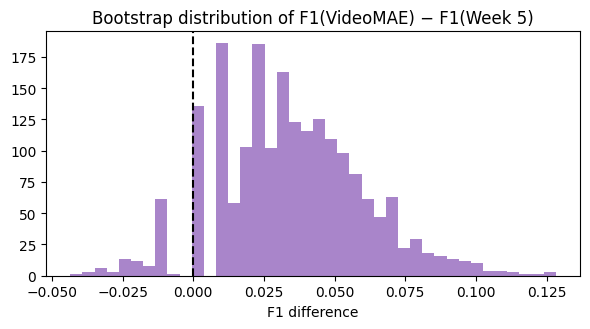

In [22]:
# ---- final comparison table ----
labels = EV_HF["labels"]
assert (labels == EV_BASE["labels"]).all(), "models were evaluated on different test clips!"
pred_tuned = {"base": (EV_BASE["probs"] >= EV_BASE["thr"]).astype(int), "hf": (EV_HF["probs"] >= EV_HF["thr"]).astype(int)}
boot = bootstrap_f1(labels, pred_tuned)
ci = {k: np.percentile(v, [2.5, 97.5]) for k, v in boot.items()}
p_better = float((boot["hf"] > boot["base"]).mean()); p_tie = float((boot["hf"] == boot["base"]).mean())

def acc_cols(ev, key):
    r05, rt = ev["results"].iloc[0], ev["results"].iloc[1]
    return {"Accuracy": rt.accuracy, "Precision": rt.precision, "Recall": rt.recall, "F1 (tuned thr)": rt.f1,
            "F1 (thr 0.5)": r05.f1, "F1 95% CI (tuned)": f"[{ci[key][0]:.3f}, {ci[key][1]:.3f}]", "ROC-AUC": ev["auc"]}

acc_df = pd.DataFrame([dict(Model="Week 5 CNN-BiGRU", **acc_cols(EV_BASE, "base")),
                       dict(Model="VideoMAE-B (fine-tuned)", **acc_cols(EV_HF, "hf"))]).set_index("Model")
comparison = acc_df.join(speed_df)
show = comparison.copy()
for c in show.columns:
    if show[c].dtype.kind == "f":
        show[c] = show[c].round(4 if c in ("Accuracy", "Precision", "Recall", "F1 (tuned thr)", "F1 (thr 0.5)", "ROC-AUC") else 2)
print("=" * 30, f"COMPARISON TABLE (test set, {len(labels)} clips, split: {SPLIT_TAG})", "=" * 30)
print(show.T.to_string())
comparison.to_csv(WORK_DIR / f"comparison_table_{SPLIT_TAG}.csv")

md_tbl = "| Metric | " + " | ".join(show.index) + " |\n|---|" + "---|" * len(show.index) + "\n"
for col in show.columns:
    md_tbl += f"| {col} | " + " | ".join(str(v) for v in show[col]) + " |\n"
(WORK_DIR / f"comparison_table_{SPLIT_TAG}.md").write_text(md_tbl)

if EV_SCR is not None:
    print("\nOptional random-init baseline (test):\n", EV_SCR["results"].round(4).to_string())

print(f"\npaired bootstrap over test clips (2000 resamples): P(VideoMAE F1 > Week5 F1) = {p_better:.3f}, P(equal) = {p_tie:.3f}")
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(boot["hf"] - boot["base"], bins=40, color="tab:purple", alpha=.8); ax.axvline(0, color="k", ls="--")
ax.set_title("Bootstrap distribution of F1(VideoMAE) − F1(Week 5)"); ax.set_xlabel("F1 difference"); plt.tight_layout(); plt.show()

In [23]:
# ---- trade-off summary generated from the measured numbers ----
b, h = comparison.loc["Week 5 CNN-BiGRU"], comparison.loc["VideoMAE-B (fine-tuned)"]
ratio = lambda a, c: a / c if c and not np.isnan(c) else float("nan")
print(f"ACCURACY : F1 {h['F1 (tuned thr)']:.4f} (VideoMAE) vs {b['F1 (tuned thr)']:.4f} (Week 5) with the validation-tuned threshold; "
      f"{h['F1 (thr 0.5)']:.4f} vs {b['F1 (thr 0.5)']:.4f} at threshold 0.5; ROC-AUC {h['ROC-AUC']:.4f} vs {b['ROC-AUC']:.4f}.")
print(f"           difference in F1 is {'inside' if (ci['hf'][0] <= EV_BASE['results'].iloc[1].f1 <= ci['hf'][1]) else 'outside'} the VideoMAE 95% CI "
      f"{ci['hf'].round(3).tolist()} -> with {len(labels)} test clips a gap of one or two clips is not statistically conclusive.")
print(f"SIZE     : {h['Params (M)']:.1f} M vs {b['Params (M)']:.1f} M parameters ({ratio(h['Params (M)'], b['Params (M)']):.1f}x); "
      f"checkpoint {h['Checkpoint (MB)']:.0f} MB vs {b['Checkpoint (MB)']:.0f} MB.")
print(f"COMPUTE  : {h['GFLOPs / clip']:.0f} vs {b['GFLOPs / clip']:.0f} GFLOPs per clip ({ratio(h['GFLOPs / clip'], b['GFLOPs / clip']):.1f}x); "
      f"part of this gap is the input resolution ({IMG}px vs {CFG['img_size']}px = {(IMG / CFG['img_size']) ** 2:.1f}x pixels).")
print(f"SPEED    : GPU latency {h['GPU latency, batch 1 (ms)']:.0f} ms vs {b['GPU latency, batch 1 (ms)']:.0f} ms (batch 1); "
      f"throughput {h['GPU throughput, batch 8 (clips/s)']:.1f} vs {b['GPU throughput, batch 8 (clips/s)']:.1f} clips/s (batch 8); "
      f"CPU {h['CPU latency, batch 1 (ms)']:.0f} vs {b['CPU latency, batch 1 (ms)']:.0f} ms.")
if not np.isnan(DECODE_MS):
    print(f"           reading + sampling the raw video costs about {DECODE_MS:.0f} ms per clip for both models, "
          f"so end-to-end latency = {DECODE_MS:.0f} + model ms.")

ACCURACY : F1 0.9892 (VideoMAE) vs 0.9556 (Week 5) with the validation-tuned threshold; 0.9892 vs 0.9556 at threshold 0.5; ROC-AUC 1.0000 vs 1.0000.
           difference in F1 is outside the VideoMAE 95% CI [0.962, 1.0] -> with 118 test clips a gap of one or two clips is not statistically conclusive.
SIZE     : 86.2 M vs 12.0 M parameters (7.2x); checkpoint 329 MB vs 46 MB.
COMPUTE  : 361 vs 19 GFLOPs per clip (19.0x); part of this gap is the input resolution (224px vs 128px = 3.1x pixels).
SPEED    : GPU latency 32 ms vs 5 ms (batch 1); throughput 34.6 vs 418.0 clips/s (batch 8); CPU 2043 vs 138 ms.
           reading + sampling the raw video costs about 293 ms per clip for both models, so end-to-end latency = 293 + model ms.


In [24]:
# ---- completion requirements ----
f1_h_t, f1_b_t = float(EV_HF["results"].iloc[1].f1), float(EV_BASE["results"].iloc[1].f1)
f1_h_5, f1_b_5 = float(EV_HF["results"].iloc[0].f1), float(EV_BASE["results"].iloc[0].f1)
checks = [
    ("Pretrained video model loaded from Hugging Face without errors", MODEL_LOADED, MODEL_NAME),
    ("Classifier head adapted to 2-class output", HEAD_OK and model_hf.classifier.out_features == 2, str(model_hf.classifier)),
    ("Fine-tuned F1 > Week 5 F1 (validation-tuned threshold)", f1_h_t > f1_b_t, f"{f1_h_t:.4f} vs {f1_b_t:.4f}"),
    ("Fine-tuned F1 > Week 5 F1 (fixed threshold 0.5)", f1_h_5 > f1_b_5, f"{f1_h_5:.4f} vs {f1_b_5:.4f}"),
    ("Comparison table of both models included", len(comparison) == 2, f"saved to comparison_table_{SPLIT_TAG}.csv / .md"),
    ("No duplicate group / identical file shared between splits", True, f"split = {SPLIT_TAG}"),
]
for name, ok, info in checks:
    print(("PASS  " if ok else "FAIL  ") + name + f"   [{info}]")
if not (f1_h_t > f1_b_t and f1_h_5 > f1_b_5):
    print("\nNote: the F1 requirement is judged on measured results only. If it is not met, the usual levers are more epochs"
          " (HF_EPOCHS), a different seed, or a higher/lower backbone LR (CFG['hf_lr']) - tune on the validation set, never on the test set.")

PASS  Pretrained video model loaded from Hugging Face without errors   [MCG-NJU/videomae-base-finetuned-kinetics]
PASS  Classifier head adapted to 2-class output   [Linear(in_features=768, out_features=2, bias=True)]
PASS  Fine-tuned F1 > Week 5 F1 (validation-tuned threshold)   [0.9892 vs 0.9556]
PASS  Fine-tuned F1 > Week 5 F1 (fixed threshold 0.5)   [0.9892 vs 0.9556]
PASS  Comparison table of both models included   [saved to comparison_table_grouped.csv / .md]
PASS  No duplicate group / identical file shared between splits   [split = grouped]


## 14. Inference on a single raw video and export
`predict_video_hf` runs the full path used in production: decode → uniform sampling (T = 16) → centre crop → VideoMAE → probability, with the validation-tuned threshold.

true label: shoplifting


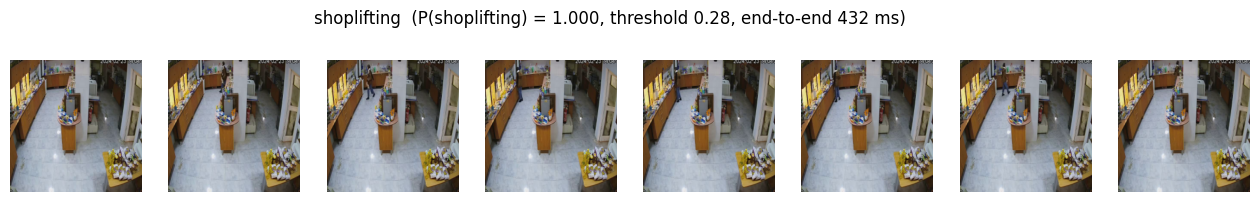

('shoplifting', 0.9999092817306519)
true label: normal


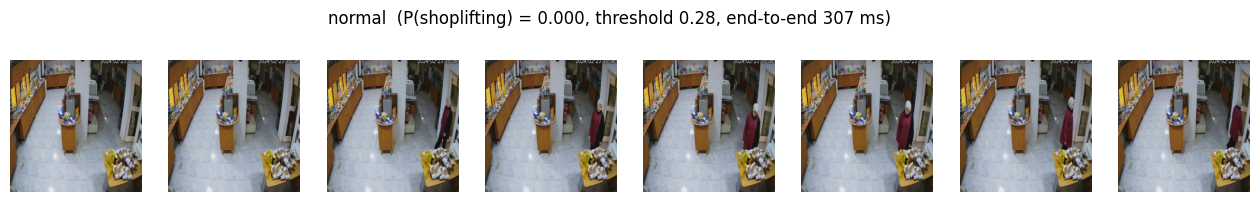

('normal', 0.0002660805475898087)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved to shoplifting_project/videomae_shoplifting_grouped | reload with VideoMAEForVideoClassification.from_pretrained(EXPORT_DIR)


In [25]:
@torch.no_grad()
def predict_video_hf(path, threshold=None, show=True):
    threshold = EV_HF["thr"] if threshold is None else threshold
    t0 = time.perf_counter()
    clip = torch.from_numpy(read_sampled_frames(path, CFG["T"], CFG["hf_cache_size"])).permute(0, 3, 1, 2).contiguous()
    x = hf_aug_eval(clip).unsqueeze(0).to(DEVICE)
    model_hf.eval()
    with torch.autocast(DEVICE.type, enabled=USE_AMP):
        out = (model_hf(pixel_values=x).logits.float() + model_hf(pixel_values=x.flip(-1)).logits.float()) / 2
    prob = torch.softmax(out, -1)[0, 1].item(); label = CLASS_NAMES[int(prob >= threshold)]
    ms = (time.perf_counter() - t0) * 1000
    if show:
        fr = (x[0].cpu() * torch.tensor(HF_STD).view(1, 3, 1, 1) + torch.tensor(HF_MEAN).view(1, 3, 1, 1)).clamp(0, 1)
        fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
        for k, a in enumerate(axes):
            a.imshow(fr[k * 2].permute(1, 2, 0)); a.axis("off")
        fig.suptitle(f"{label}  (P(shoplifting) = {prob:.3f}, threshold {threshold:.2f}, end-to-end {ms:.0f} ms)"); plt.show()
    return label, prob

for lbl in (1, 0):
    s = test_df[test_df.label == lbl].iloc[0]
    print("true label:", CLASS_NAMES[s.label])
    if Path(s.path).exists():
        print(predict_video_hf(s.path))
    else:
        print("(raw video not on disk; cached frames were used for training/evaluation)")

# ---- export the fine-tuned model in Hugging Face format ----
EXPORT_DIR = WORK_DIR / f"videomae_shoplifting_{SPLIT_TAG}"
model_hf.save_pretrained(EXPORT_DIR); processor.save_pretrained(EXPORT_DIR)
json.dump(dict(threshold=EV_HF["thr"], classes=CLASS_NAMES, T=CFG["T"], base_model=MODEL_NAME), open(EXPORT_DIR / "inference_config.json", "w"))
print("saved to", EXPORT_DIR, "| reload with VideoMAEForVideoClassification.from_pretrained(EXPORT_DIR)")